# Entrega 3 · Modelado de etapas del sueño · Revisión

**Estado: salidas de Kaggle incorporadas hasta 4.5.2; 4.5.3–4.6 y la comparación adicional siguen pendientes.** Las salidas corresponden a 16 configuraciones de hiperparámetros, ejecutadas con `N_JOBS=2`. La configuración vigente conserva `N_JOBS=-1` para futuras ejecuciones, según lo acordado; los tiempos guardados pertenecen a la ejecución anterior. En 4.5.1 se conservaron exactamente las tablas comparativas finales de Kaggle; se retiraron únicamente las tablas detalladas de cada prueba, sin reentrenar ni recalcular cifras.

Copia de revisión de `temporal_version_tp_entrega03.ipynb`. Todos los modelos utilizan wearable + PSG para identificar la etapa del epoch actual de 30 segundos.

Se elige un candidato mediante pacientes separados y otro mediante epochs mezclados, usando el mismo catálogo de alternativas. Una comparación posterior con pacientes adicionales permitirá evaluar ambos en personas nuevas. Los 16 pacientes del test histórico no se utilizan para nuevos ajustes.

Ejecutar 4.1–4.6 desde un kernel limpio. `N_JOBS=-1` conserva el uso de los núcleos de CPU disponibles del notebook original para RF y XGBoost; este código no configura GPU ni TPU. La sección 4.7 requiere los dos CSV de pacientes adicionales procesados con las mismas reglas del ETL; sin ellos informa el pendiente. La sección 4.8 conserva el código y las salidas históricas del notebook original como referencia posterior: **no ejecutar sus celdas**.

Salidas nuevas: `output/modelado_revision/` en local o `/kaggle/working/modelado_revision/`. El notebook oficial y sus resultados históricos se conservan durante la revisión. Los registros de ejecución distinguen pruebas ejecutadas y resultados reutilizados.

La selección de algoritmos, los protocolos y los diagnósticos son decisiones del proyecto. Las asociaciones descriptivas no demuestran rendimiento predictivo; las cifras de los dos protocolos responden preguntas distintas.


## 4.1. Datos, test histórico y particiones

Se conserva la reserva por paciente y semilla 42: 45.011 epochs de 60 pacientes para desarrollo; 11.839 epochs de 16 pacientes ya evaluados históricamente. La identidad, el tiempo y Sleep_Stage quedan fuera de X.

En desarrollo se utilizan cinco folds de StratifiedGroupKFold por paciente y cinco de StratifiedKFold con epochs mezclados. Cada protocolo reutiliza sus propias particiones en todos los modelos. La estratificación intenta conservar proporciones; no balancea las clases. Se comprueba la cobertura de las cinco etapas y que cada epoch tenga una sola predicción de validación.

Pacientes separados exige personas distintas en entrenamiento y validación. Epochs mezclados admite pacientes compartidos y observaciones próximas. El test histórico queda apartado de los nuevos ajustes. No se realiza evaluación cronológica; los retardos causales de señales se mantienen como características.


In [1]:
from pathlib import Path
import hashlib
import copy
import sys
import importlib.metadata
import importlib.util
import json
import platform
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from IPython import get_ipython
if getattr(get_ipython(), 'kernel', None) is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Instalación local opcional; en Kaggle se usa el entorno del notebook.
for carpeta_dependencias in [Path('output/modelado-deps'), Path('../output/modelado-deps')]:
    if carpeta_dependencias.is_dir():
        sys.path.insert(0, str(carpeta_dependencias.resolve()))


def mostrar_tabla(tabla, titulo=None):
    """HTML completo, sin límites globales de pandas ni reducción de fuente."""
    if titulo:
        display(Markdown(f'**{titulo}**'))
    tiene_indice = not isinstance(tabla.index, pd.RangeIndex)
    html = tabla.to_html(index=tiene_indice, border=0, max_rows=None, max_cols=None,
                         float_format=lambda v: f'{v:.4f}', na_rep='—', escape=True)
    display(HTML('<div style="overflow-x:auto; margin-bottom:1em">' + html + '</div>'))

def nombre_protocolo(protocolo):
    return {'pacientes': 'Pacientes separados', 'epochs': 'Epochs mezclados'}[protocolo]

def nombre_algoritmo(algoritmo):
    return {'Baseline': 'Referencia trivial', 'Logistica': 'Regresión logística',
            'RF': 'Random Forest', 'XGB': 'XGBoost'}.get(algoritmo, algoritmo)

SEMILLA = 42
N_SPLITS = 5
N_JOBS = -1  # Configuración original: utilizar los núcleos de CPU disponibles.
ETAPAS = ['W', 'N1', 'N2', 'N3', 'R']
CLAVES = ['patient_id', 'epoch']
EN_KAGGLE = platform.system() != 'Windows' and Path('/kaggle/input').is_dir()
SALIDA = Path('/kaggle/working/modelado_revision') if EN_KAGGLE else Path('output/modelado_revision')
SALIDA.mkdir(parents=True, exist_ok=True)

def guardar_json(ruta, objeto):
    ruta.write_text(json.dumps(objeto, ensure_ascii=False, indent=2, default=str), encoding='utf-8')

def buscar_csv(nombre):
    # Una ubicación explícita evita elegir silenciosamente entre copias Kaggle.
    locales = [Path('etl_v1') / nombre, Path('../etl_v1') / nombre]
    archivos = [p.resolve() for p in locales if p.exists()]
    if not archivos and EN_KAGGLE:
        archivos = list(Path('/kaggle/input').rglob(nombre))
    archivos = list(dict.fromkeys(archivos))
    if len(archivos) != 1:
        raise FileNotFoundError(f'{nombre}: se esperaba una única fuente; encontradas {archivos}')
    return archivos[0]

ruta_base = buscar_csv('dataset_epochs_v1.csv')
ruta_candidato = buscar_csv('dataset_modelado_candidato.csv')
base = pd.read_csv(ruta_base, low_memory=False)
candidato = pd.read_csv(ruta_candidato, low_memory=False)
versiones = {'python': platform.python_version(), **{
    paquete: importlib.metadata.version(paquete)
    for paquete in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'imbalanced-learn']}}
versiones['xgboost'] = (importlib.metadata.version('xgboost')
    if importlib.util.find_spec('xgboost') else 'no instalado')
guardar_json(SALIDA / 'versiones.json', versiones)
mostrar_tabla(pd.DataFrame([{'fuente': 'ETL', 'epochs': len(base), 'columnas': base.shape[1]},
                      {'fuente': 'candidato', 'epochs': len(candidato), 'columnas': candidato.shape[1]}]))

def agregar_historia(entradas, tabla, minutos):
    """Solo pasado exacto dentro de segmentos de epochs contiguos de 30 s."""
    if not entradas.index.equals(tabla.index):
        raise ValueError('Historia desalineada')
    salida = entradas.copy()
    disponibilidad = []
    for _, grupo in tabla.groupby('patient_id', sort=False):
        orden = grupo.sort_values('tiempo_relativo_segundos').index
        tiempos = tabla.loc[orden, 'tiempo_relativo_segundos']
        if tiempos.duplicated().any() or not np.isfinite(tiempos).all():
            raise ValueError('Tiempos inválidos para historia')
    ordenada = tabla.sort_values(['patient_id', 'tiempo_relativo_segundos'])
    salto = ordenada.groupby('patient_id').tiempo_relativo_segundos.diff()
    segmentos = (~np.isclose(salto.to_numpy(), 30.0, atol=1e-6, rtol=0)).cumsum()
    grupos = ordenada.assign(segmento=segmentos).groupby(['patient_id','segmento'], sort=False)
    for minuto in minutos:
        pasos = int(round(minuto * 2))
        if pasos <= 0 or not np.isclose(pasos * 30, minuto * 60):
            raise ValueError('Retardo no compatible con epochs de 30 segundos')
        columnas = [f'{c}__lag{minuto}m' for c in entradas]
        historia = pd.DataFrame(np.nan, index=entradas.index, columns=entradas.columns)
        for _, grupo in grupos:
            historia.loc[grupo.index] = entradas.loc[grupo.index].shift(pasos).to_numpy()
        historia.columns = columnas
        indicador = f'historia_disponible__lag{minuto}m'
        salida = pd.concat([salida, historia], axis=1)
        salida[indicador] = historia.notna().all(axis=1).astype(int)
        disponibilidad.append(dict(minutos=minuto, disponibles=int(salida[indicador].sum()),
            faltantes=int((salida[indicador] == 0).sum()), fraccion=float(salida[indicador].mean())))
    return salida, pd.DataFrame(disponibilidad)

# Si no hay exportaciones completas y compatibles, se vuelven a ejecutar las pruebas.
# Solo se reutilizan artefactos de revisión con datos, folds, parámetros y entorno idénticos.


fuente,epochs,columnas
ETL,56850,128
candidato,56850,26


In [2]:
columnas_principal = [
    'HR_median', 'HR_std', 'TEMP_median', 'EDA_std',
    'C4-M1_std', 'F4-M1_std', 'O2-M1_std', 'Fp1-O2_std',
    'T3 - CZ_std', 'CZ - T4_std', 'CHIN_std', 'ECG_std',
    'SNORE_std', 'PTAF_std', 'FLOW_std', 'THORAX_std', 'ABDOMEN_std',
    'EOG_max_std', 'LEG_max_std', 'BVP_std_log1p',
    'EDA_median_log1p', 'ACC_axes_std_norm_log1p']
for nombre, tabla in [('ETL', base), ('candidato', candidato)]:
    if tabla[CLAVES + ['Sleep_Stage']].isna().any().any():
        raise ValueError(f'{nombre}: identidad u objetivo faltante')
    if tabla.duplicated(CLAVES).any():
        raise ValueError(f'{nombre}: claves repetidas')
    if not tabla.Sleep_Stage.isin(ETAPAS).all():
        raise ValueError(f'{nombre}: etapas inválidas')
base = base.sort_values(CLAVES).reset_index(drop=True)
candidato = candidato.sort_values(CLAVES).reset_index(drop=True)
if not base[CLAVES + ['Sleep_Stage']].equals(candidato[CLAVES + ['Sleep_Stage']]):
    raise ValueError('Los CSV no tienen la misma cohorte, claves y etiquetas. '
                     'Exportar ambos desde la misma ejecución; no se recortan ni reconstruyen datos.')
assert not set(columnas_principal) & set(CLAVES + ['Sleep_Stage', 'tiempo_relativo_segundos'])
if not np.isfinite(candidato[columnas_principal].to_numpy(dtype=float)).all():
    raise ValueError('Hay predictores faltantes o infinitos; revisar ETL.')

# Huella de ambos archivos: una asignación guardada no se reutiliza con otros datos.
def sha256_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()
huella = {p.name: sha256_archivo(p) for p in [ruta_base, ruta_candidato]}
ruta_asignacion = SALIDA / 'asignacion_pacientes.json'
pacientes_test_congelados = [2, 6, 12, 14, 20, 30, 35, 37, 48, 50, 53, 56, 67, 83, 85, 88]
if ruta_asignacion.exists():
    asignacion = json.loads(ruta_asignacion.read_text(encoding='utf-8'))
    if asignacion['huella'] != huella or asignacion['semilla'] != SEMILLA:
        raise ValueError('Cambió la fuente/semilla: conservar las salidas anteriores y usar otra carpeta SALIDA.')
    pacientes_test = asignacion['pacientes_test']
else:
    pacientes_test = pacientes_test_congelados
    asignacion = {'huella': huella, 'semilla': SEMILLA, 'fraccion_pacientes_test': 0.2,
                  'pacientes_test': pacientes_test,
                  'exposicion_previa': 'EDA y comparaciones anteriores sobre la cohorte completa'}

if pacientes_test != pacientes_test_congelados:
    raise ValueError('La reserva difiere de la evaluación histórica; no cambiar pacientes.')
es_test = base.patient_id.isin(pacientes_test)
for nombre, tabla in [('desarrollo', base.loc[~es_test]), ('test', base.loc[es_test])]:
    if set(tabla.Sleep_Stage) != set(ETAPAS):
        raise ValueError(f'{nombre}: falta alguna etapa. Revisar cobertura antes de entrenar, sin elegir por desempeño.')
guardar_json(ruta_asignacion, asignacion)
asignacion_csv = base[CLAVES].assign(conjunto=np.where(es_test, 'test', 'desarrollo'))
asignacion_csv.to_csv(SALIDA / 'asignacion_epochs.csv', index=False)
dev = candidato.loc[~es_test].reset_index(drop=True)
base_dev = base.loc[~es_test].reset_index(drop=True)
test = candidato.loc[es_test].reset_index(drop=True)
assert not set(dev.patient_id) & set(test.patient_id)
assert len(dev) + len(test) == len(base)
y = dev.Sleep_Stage.map({e: i for i, e in enumerate(ETAPAS)}).to_numpy()
X = dev[columnas_principal]
folds = {
    'pacientes': list(StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEMILLA)
                      .split(X, y, dev.patient_id)),
    'epochs': list(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEMILLA).split(X, y))}
controles, asignaciones_folds, pacientes_folds = [], [], []
for protocolo, rondas in folds.items():
    cobertura = np.zeros(len(dev), dtype=int)
    for fold, (tr, va) in enumerate(rondas, 1):
        assert not set(tr) & set(va)
        assert len(tr) + len(va) == len(dev)
        if protocolo == 'pacientes':
            assert not set(dev.iloc[tr].patient_id) & set(dev.iloc[va].patient_id)
        pacientes_folds.append({'protocolo': protocolo, 'Fold': fold,
            'Entrenamiento': dev.iloc[tr].patient_id.nunique(),
            'Validación': dev.iloc[va].patient_id.nunique(),
            'Compartidos': len(set(dev.iloc[tr].patient_id) & set(dev.iloc[va].patient_id))})
        cobertura[va] += 1
        asignaciones_folds.append(dev.iloc[va][CLAVES].assign(protocolo=protocolo, fold=fold))
        for conjunto, idx in [('entrenamiento', tr), ('validacion', va)]:
            if set(y[idx]) != set(range(5)):
                raise ValueError(f'{protocolo}, fold {fold}: cobertura incompleta')
            for codigo, etapa in enumerate(ETAPAS):
                controles.append(dict(protocolo=protocolo, fold=fold, conjunto=conjunto,
                    etapa=etapa, epochs=int((y[idx] == codigo).sum()),
                    pacientes=dev.iloc[idx].loc[y[idx] == codigo, 'patient_id'].nunique()))
    assert (cobertura == 1).all()
asignacion_actual = pd.concat(asignaciones_folds).reset_index(drop=True)
if (SALIDA / 'folds_validacion.csv').exists():
    pd.testing.assert_frame_equal(pd.read_csv(SALIDA / 'folds_validacion.csv'), asignacion_actual, check_dtype=False, obj='Folds previamente fijados')
asignacion_actual.to_csv(SALIDA / 'folds_validacion.csv', index=False)
pd.DataFrame(controles).to_csv(SALIDA / 'cobertura_folds.csv', index=False)

mostrar_tabla(asignacion_csv.groupby('conjunto').agg(Pacientes=('patient_id', 'nunique'))
              .rename_axis('Conjunto'), 'Reserva de pacientes')
pacientes_folds = pd.DataFrame(pacientes_folds)
pacientes_folds.to_csv(SALIDA / 'pacientes_por_fold.csv', index=False)
for protocolo in folds:
    tabla = pacientes_folds.loc[pacientes_folds.protocolo.eq(protocolo)].drop(columns='protocolo').reset_index(drop=True)
    mostrar_tabla(tabla, f'Pacientes por fold — {nombre_protocolo(protocolo)}')
print('Cobertura de las cinco etapas verificada. Detalle por etapa guardado en cobertura_folds.csv.')

# Estas huellas identifican exactamente los folds; las versiones se registran en 4.1.
huellas_folds = {p: hashlib.sha256(b''.join(
    np.asarray(idx, dtype='<i8').tobytes() for tr, va in rondas for idx in (tr, va)
)).hexdigest() for p, rondas in folds.items()}
guardar_json(SALIDA / 'huellas_folds.json', huellas_folds)


**Reserva de pacientes**

,Pacientes
Conjunto,
desarrollo,60
test,16


**Pacientes por fold — Pacientes separados**

Fold,Entrenamiento,Validación,Compartidos
1,49,11,0
2,47,13,0
3,48,12,0
4,47,13,0
5,49,11,0


**Pacientes por fold — Epochs mezclados**

Fold,Entrenamiento,Validación,Compartidos
1,60,60,60
2,60,60,60
3,60,60,60
4,60,60,60
5,60,60,60


Cobertura de las cinco etapas verificada. Detalle por etapa guardado en cobertura_folds.csv.


## 4.2. Configuraciones y reproducibilidad
DummyClassifier es el piso; logística es la referencia lineal. RF y XGBoost capturan
interacciones no lineales. Ninguno es ganador por definición. Semilla y núcleos controlan
reproducibilidad/costo, no se optimizan como capacidad predictiva.
Los hiperparámetros, sus efectos y las variaciones están documentados en
`docs/entrega-03/experimentos-hiperparametros.md`. No hay SMOTE inicial.


### Referencia trivial

Se utiliza `DummyClassifier` con la estrategia `most_frequent`: en cada fold identifica la etapa más frecuente del entrenamiento y la predice para todos los epochs de validación.

Este baseline establece una referencia mínima. Los modelos posteriores deberían mejorar su desempeño, especialmente en F1 macro y en el reconocimiento de las etapas minoritarias. Se evalúa con las mismas particiones y métricas que los demás candidatos.

### Regresión logística multiclase

Se utiliza regresión logística como referencia lineal para clasificar las cinco etapas. Las variables se estandarizan con `StandardScaler`, ajustado únicamente con el entrenamiento de cada fold.

Configuración inicial:

* `C=1.0`: controla la intensidad de la regularización, que penaliza coeficientes grandes para limitar ajustes demasiado específicos al entrenamiento. Un C menor aplica mayor regularización; uno mayor, menor. Se utiliza 1 como referencia inicial, sin considerarlo óptimo.
* `solver="lbfgs"`: algoritmo de optimización que encuentra los coeficientes del modelo. Permite ajustar la clasificación multiclase.
* `max_iter=2000`: máximo de iteraciones del optimizador. Si converge antes, se detiene antes. Este límite busca permitir que termine el ajuste; no garantiza mejores predicciones.
* `escalar=True`: activa la estandarización dentro del Pipeline. Cada variable se centra y divide por su desviación estándar calculada en entrenamiento.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos. En 4.4 se compara también con pesos, manteniendo los demás parámetros.

### Random Forest

Random Forest combina árboles de decisión entrenados con variaciones en los datos y las características consideradas. Permite representar relaciones no lineales e interacciones entre señales.

Configuración inicial:

* `n_estimators=200`: cantidad de árboles del bosque. Se parte de 200 para obtener una primera referencia con un costo de ejecución acotado.
* `min_samples_leaf=2`: cada hoja debe contener al menos dos observaciones de entrenamiento. Limita hojas demasiado específicas, aunque no garantiza evitar el sobreajuste.
* `max_features="sqrt"`: en cada división se considera un subconjunto aleatorio de características cuyo tamaño depende de la raíz cuadrada del número de predictores. Favorece que los árboles sean diferentes entre sí.
* `escalar=False`: no se estandarizan las variables; los árboles realizan divisiones mediante umbrales por característica.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos.

Opciones de ejecución:

* `random_state=SEMILLA`: fija la aleatoriedad para poder reproducir el experimento con los mismos datos y configuración.
* `n_jobs=N_JOBS`: permite utilizar los núcleos de CPU disponibles para paralelizar el trabajo.

### XGBoost

XGBoost aplica gradient boosting: incorpora árboles secuencialmente para reducir la función de pérdida del conjunto. Se evalúa como candidato para capturar relaciones no lineales entre las señales.

Configuración inicial:

* `objective="multi:softprob"`: define un problema de clasificación multiclase y permite obtener probabilidades para cada etapa.
* `num_class=5`: indica las cinco clases: W, N1, N2, N3 y R.
* `n_estimators=200`: establece 200 rondas de boosting. En clasificación multiclase, una ronda puede incorporar varios árboles.
* `max_depth=4`: limita la profundidad de los árboles. Se parte de árboles relativamente acotados para controlar complejidad y costo.
* `learning_rate=0.1`: reduce la contribución de cada ronda al conjunto. Valores menores suelen requerir más rondas para aprender.
* `subsample=0.8`: utiliza una muestra aleatoria del 80 % de las observaciones de entrenamiento en cada ronda.
* `colsample_bytree=0.8`: utiliza una muestra aleatoria del 80 % de las características al construir cada árbol. Ambos muestreos introducen variación y pueden ayudar a limitar el sobreajuste.
* `eval_metric="mlogloss"`: configura la pérdida logarítmica multiclase como métrica interna. La comparación entre candidatos sigue usando F1 macro como métrica principal. En esta ejecución no se utiliza early stopping.
* `escalar=False`: se mantienen las escalas de las variables para este modelo basado en árboles.
* `usar_pesos=False`: define la referencia sin ponderación; también se entrena la alternativa con pesos.

Opciones de ejecución:

* `tree_method="hist"`: utiliza histogramas para buscar divisiones de forma eficiente.
* `random_state=SEMILLA`: fija la aleatoriedad del experimento.
* `n_jobs=N_JOBS`: permite utilizar los núcleos de CPU disponibles.


In [3]:
def modelos_referencia():
    try:
        from xgboost import XGBClassifier
    except ImportError as exc:
        raise ImportError('Instalar xgboost en el entorno elegido antes de entrenar; no se omite el candidato.') from exc
    return {
        'Baseline': (DummyClassifier(strategy='most_frequent'), False),
        'Logistica': (LogisticRegression(C=1, solver='lbfgs', max_iter=2000), True),
        'RF': (RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                 max_features='sqrt', random_state=SEMILLA, n_jobs=N_JOBS), False),
        'XGB': (XGBClassifier(objective='multi:softprob', num_class=5, n_estimators=200,
                 max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                 tree_method='hist', eval_metric='mlogloss', random_state=SEMILLA, n_jobs=N_JOBS), False)}


## 4.3. Evaluación común
`X` contiene predictores; `y`, las cinco etapas codificadas; pacientes e identidad quedan aparte.
Cada fold crea un pipeline nuevo. El escalado y los pesos se ajustan únicamente en entrenamiento.
Peso balanceado por clase: `N_train / (5 * N_clase_train)`; no combina además `class_weight`.

Guardamos métricas de entrenamiento y validación, tiempos y probabilidades OOF:
cada epoch elegible recibe una predicción de validación por configuración. F1 macro da igual peso a las
cinco etapas; soporte es cantidad real de ejemplos. Brecha alta con entrenamiento sugiere
sobreajuste; ambos resultados bajos no identifican por sí solos su causa.


El pipeline reúne preprocesamiento y clasificador: se crea una instancia nueva por fold.
Logística estandariza con StandardScaler aprendido en entrenamiento; los árboles no lo necesitan.
Las probabilidades se guardan en orden explícito para construir curvas posteriormente.
En pacientes separados, una predicción OOF nunca proviene de un modelo que vio a esa persona;
con epochs mezclados, esa garantía se limita al epoch retenido.

**Cómo leer las métricas:** precisión indica qué proporción de detecciones de una etapa es
correcta; recuperación, qué proporción de sus casos reales se detectó. F1 combina ambas:
`2 × precisión × recuperación / (precisión + recuperación)`. F1 macro promedia los cinco F1
con igual peso. Exactitud es la fracción total de aciertos y soporte es cantidad de casos reales.
La referencia trivial puede acertar N2 frecuentemente sin reconocer las otras cuatro etapas.

**Pesos automáticos:** compute_sample_weight("balanced") asigna `N_train / (5 × N_clase_train)`
a cada observación. Se recalculan dentro del fold, no crean ejemplos y pueden aumentar
recuperación minoritaria a costa de falsos positivos. Validación y test no se ponderan.
La tabla de pesos por etapa queda exportada con cada experimento.
Los códigos 0–4 identifican clases; no representan un orden entre etapas. Las señales PSG pueden entrar en X, pero Sleep_Stage es exclusivamente y.

SMOTE y contexto temporal se comparan por separado, con preprocesamiento ajustado por fold.


In [4]:
def crear_pipeline(modelo, escalar=False, imputar=False, smote=None):
    pasos = [('imputacion', SimpleImputer(strategy='median', keep_empty_features=True) if imputar else 'passthrough'),
             ('escala', StandardScaler() if escalar or smote else 'passthrough')]
    if smote:
        from imblearn.over_sampling import SMOTE
        from imblearn.pipeline import Pipeline as PipelineMuestreo
        pasos += [('smote', SMOTE(sampling_strategy=smote['cantidades'],
                                  k_neighbors=smote['k'], random_state=SEMILLA)), ('modelo', clone(modelo))]
        return PipelineMuestreo(pasos)
    return Pipeline(pasos + [('modelo', clone(modelo))])

def _evaluar_sin_cache(modelo, entradas, nombre, protocolo, pesos=False, escalar=False, importancia=False,
            mostrar_progreso=True, imputar=False, smote=None):
    if (not entradas.index.equals(dev.index) or np.isinf(entradas.to_numpy(float)).any()
        or (not imputar and entradas.isna().any().any())):
        raise ValueError('Entradas desalineadas o no finitas')
    if set(entradas.columns) & set(CLAVES + ['Sleep_Stage', 'tiempo_relativo_segundos']):
        raise ValueError('Identificador, tiempo u objetivo entre entradas')
    metricas, etapas, predicciones, pesos_folds, importancias = [], [], [], [], []
    muestreo = []
    if smote and pesos:
        raise ValueError('No combinar SMOTE y pesos en esta ronda')
    for numero, (tr, va) in enumerate(folds[protocolo], 1):
        opciones_smote = None
        cantidades = np.bincount(y[tr], minlength=5)
        if smote:
            objetivo = int(np.ceil(cantidades.max() * smote['ratio']))
            estrategia = {c: max(int(n), objetivo) for c,n in enumerate(cantidades)}
            if cantidades.min() <= smote['k']:
                raise ValueError('SMOTE sin vecinos suficientes; no modificar k silenciosamente')
            opciones_smote = dict(k=smote['k'], cantidades=estrategia)
        pipe = crear_pipeline(modelo, escalar, imputar, opciones_smote)
        for c,e in enumerate(ETAPAS):
            muestreo.append(dict(fold=numero, etapa=e, reales=int(cantidades[c]),
                sinteticos=0 if not smote else estrategia[c]-int(cantidades[c])))
        w = compute_sample_weight('balanced', y[tr]) if pesos else np.ones(len(tr))
        for c, etapa in enumerate(ETAPAS):
            pesos_folds.append(dict(fold=numero, etapa=etapa, epochs=int((y[tr] == c).sum()),
                                    peso=float(w[y[tr] == c][0])))
        inicio = perf_counter()
        if smote:
            pipe.fit(entradas.iloc[tr], y[tr])
        else:
            pipe.fit(entradas.iloc[tr], y[tr], modelo__sample_weight=w)
        t_fit = perf_counter() - inicio
        for conjunto, idx in [('entrenamiento', tr), ('validacion', va)]:
            inicio = perf_counter()
            pred = pipe.predict(entradas.iloc[idx]).astype(int)
            prob = pipe.predict_proba(entradas.iloc[idx]) if conjunto == 'validacion' else None
            t_pred = perf_counter() - inicio
            metricas.append(dict(experimento=nombre, protocolo=protocolo, pesos=pesos,
                fold=numero, conjunto=conjunto,
                f1_macro=f1_score(y[idx], pred, labels=range(5), average='macro', zero_division=0),
                exactitud=accuracy_score(y[idx], pred), segundos_entrenamiento=t_fit,
                segundos_prediccion=t_pred))
            p, r, f, s = precision_recall_fscore_support(y[idx], pred, labels=range(5), zero_division=0)
            for c, etapa in enumerate(ETAPAS):
                etapas.append(dict(fold=numero, conjunto=conjunto, etapa=etapa,
                    precision=p[c], recuperacion=r[c], f1=f[c], soporte=int(s[c])))
            if conjunto == 'validacion':
                assert np.array_equal(pipe.classes_, np.arange(5))
                assert np.isfinite(prob).all() and np.allclose(prob.sum(axis=1), 1)
                salida = dev.iloc[idx][CLAVES + ['tiempo_relativo_segundos']].copy()
                salida['fold'] = numero
                salida['real'] = y[idx]
                salida['predicha'] = pred
                for c, etapa in enumerate(ETAPAS):
                    salida[f'prob_{etapa}'] = prob[:, c]
                predicciones.append(salida)
        if importancia:
            resultado = permutation_importance(pipe, entradas.iloc[va], y[va],
                scoring='f1_macro', n_repeats=5, random_state=SEMILLA + numero, n_jobs=1)
            for j, variable in enumerate(entradas.columns):
                for repeticion, valor in enumerate(resultado.importances[j], 1):
                    importancias.append(dict(fold=numero, variable=variable,
                                              repeticion=repeticion, caida_f1_macro=valor))
        if mostrar_progreso:
            print(f'Fold {numero}/{len(folds[protocolo])} terminado.', flush=True)
    oof = pd.concat(predicciones).sort_index()
    elegibles = np.sort(np.concatenate([va for _,va in folds[protocolo]]))
    assert len(np.unique(elegibles)) == len(elegibles)
    assert np.array_equal(oof.index.to_numpy(), elegibles) and not oof.duplicated(CLAVES).any()
    resultado = dict(metricas=pd.DataFrame(metricas), etapas=pd.DataFrame(etapas),
        oof=oof, pesos=pd.DataFrame(pesos_folds), importancia=pd.DataFrame(importancias),
        configuracion=dict(nombre=nombre, protocolo=protocolo, pesos=pesos, escalar=escalar,
                           columnas=list(entradas.columns), parametros=modelo.get_params(), imputar=imputar, smote=smote),
        muestreo=pd.DataFrame(muestreo))
    carpeta = SALIDA / nombre
    carpeta.mkdir(exist_ok=True)
    for clave in ['metricas', 'etapas', 'oof', 'pesos', 'importancia', 'muestreo']:
        resultado[clave].to_csv(carpeta / f'{clave}.csv', index=False)
    guardar_json(carpeta / 'configuracion.json', resultado['configuracion'])
    return resultado



CODIGO_EVALUADOR_SHA256 = 'aae647f4b6f772da80818eb7e51459b46fb3ade6cfeee1dd7fdb61a278f8134c'

_cache_evaluaciones = {}
for _ruta in SALIDA.glob('*/identidad_evaluacion.json'):
    _identidad = json.loads(_ruta.read_text())
    _cache_evaluaciones[_identidad['sha256']] = _ruta.parent


def evaluar(modelo, entradas, nombre, protocolo, pesos=False, escalar=False, importancia=False,
            mostrar_progreso=True, imputar=False, smote=None):
    identidad = dict(parametros=modelo.get_params(), modelo=type(modelo).__name__,
        protocolo=protocolo, pesos=pesos, escalar=escalar, importancia=importancia,
        imputar=imputar, smote=smote, columnas=list(entradas.columns),
        fuentes=huella, folds=huellas_folds[protocolo], versiones=versiones,
        algoritmo_evaluacion='revision-v1',
        codigo=CODIGO_EVALUADOR_SHA256,
        entradas=hashlib.sha256(pd.util.hash_pandas_object(entradas,index=True).values.tobytes()).hexdigest(),
        objetivo=hashlib.sha256(np.asarray(y,dtype='<i8').tobytes()).hexdigest())
    digest = hashlib.sha256(json.dumps(identidad,sort_keys=True,default=str).encode()).hexdigest()
    carpeta_previa = _cache_evaluaciones.get(digest)
    claves = ['metricas','etapas','oof','pesos','importancia','muestreo']
    if carpeta_previa is not None:
        sello = json.loads((carpeta_previa/'identidad_evaluacion.json').read_text())
        if any(not (carpeta_previa/f).exists() or sha256_archivo(carpeta_previa/f)!=h
               for f,h in sello['archivos'].items()):
            raise ValueError('La caché no coincide con sus huellas; conservarla y revisar.')
        resultado = {'configuracion': copy.deepcopy(sello['configuracion'])}
        for clave in claves:
            try: resultado[clave] = pd.read_csv(carpeta_previa/f'{clave}.csv')
            except pd.errors.EmptyDataError: resultado[clave] = pd.DataFrame()
        indices = pd.MultiIndex.from_frame(dev[CLAVES]).get_indexer(
            pd.MultiIndex.from_frame(resultado['oof'][CLAVES]))
        if (indices<0).any(): raise ValueError('Caché OOF de otra cohorte')
        resultado['oof'].index = indices
        resultado['oof'] = resultado['oof'].sort_index()
        elegibles=np.sort(np.concatenate([va for _,va in folds[protocolo]]))
        if not np.array_equal(resultado['oof'].index,elegibles):
            raise ValueError('Caché sin cobertura OOF completa')
        resultado['metricas']['experimento'] = nombre
        resultado['configuracion']['nombre'] = nombre
        resultado['configuracion']['reutilizado_de'] = str(carpeta_previa)
        print(f'Reutilizado: {carpeta_previa.name}; tiempos del entrenamiento original.',flush=True)
    else:
        resultado = _evaluar_sin_cache(modelo,entradas,nombre,protocolo,pesos,escalar,
            importancia,mostrar_progreso,imputar,smote)
    carpeta = SALIDA/nombre
    carpeta.mkdir(exist_ok=True)
    for clave in claves:
        resultado[clave].to_csv(carpeta/f'{clave}.csv',index=False)
    guardar_json(carpeta/'configuracion.json',resultado['configuracion'])
    guardar_json(carpeta/'identidad_evaluacion.json',dict(sha256=digest,
        identidad=identidad, configuracion=resultado['configuracion'],
        archivos={f'{k}.csv':sha256_archivo(carpeta/f'{k}.csv') for k in claves}))
    _cache_evaluaciones[digest]=carpeta
    return resultado


def algoritmo_resultado(nombre):
    for algoritmo in ['Baseline', 'Logistica', 'RF', 'XGB']:
        if f'_{algoritmo}_' in nombre or nombre.endswith('_' + algoritmo):
            return algoritmo
    return nombre

def etiqueta_resultado(nombre, resultado):
    if resultado['configuracion'].get('descripcion'):
        return (resultado['configuracion']['descripcion'].replace('sin_log_combinada','sin log1p; canales combinados').replace('separada_con_log','canales separados; con log1p').replace('candidata','representación candidata') + (' · pesos balanceados' if resultado['configuracion']['pesos'] else ' · sin pesos'))
    algoritmo = algoritmo_resultado(nombre)
    texto = nombre_algoritmo(algoritmo)
    if algoritmo != 'Baseline':
        texto += ' con pesos' if resultado['configuracion']['pesos'] else ' sin pesos'
    if nombre.startswith('ajuste_'):
        cambio = nombre.split('_pesos', 1)[1].split('_', 1)[1]
        parametro, valor = cambio.rsplit('_', 1)
        texto += f' · {parametro}={valor}'
    elif nombre.startswith('representacion_'):
        variante = nombre.split('_', 2)[2]
        texto += ' · ' + {'candidata': 'candidata', 'sin_log_combinada': 'sin log1p',
                          'separada_con_log': 'canales separados'}.get(variante, variante)
    return texto

def construir_resumen(resultados):
    filas = []
    for nombre, r in resultados.items():
        m = r['metricas']
        va = m.loc[m.conjunto.eq('validacion')]
        tr = m.loc[m.conjunto.eq('entrenamiento')]
        filas.append(dict(experimento=nombre, f1_macro=va.f1_macro.mean(),
            desviacion=va.f1_macro.std(), f1_train=tr.f1_macro.mean(),
            brecha=tr.f1_macro.mean() - va.f1_macro.mean(), exactitud=va.exactitud.mean(),
            segundos_entrenamiento=va.segundos_entrenamiento.sum(),
            segundos_prediccion=va.segundos_prediccion.sum()))
    return pd.DataFrame(filas).set_index('experimento').sort_values('f1_macro', ascending=False)

def mostrar_resultados_modelo(resultado):
    m = resultado['metricas']
    va = m.loc[m.conjunto.eq('validacion')].set_index('fold')
    tr = m.loc[m.conjunto.eq('entrenamiento')].set_index('fold')
    mostrar_tabla(va[['f1_macro', 'exactitud', 'segundos_entrenamiento', 'segundos_prediccion']]
        .rename(columns={'f1_macro': 'F1 macro', 'exactitud': 'Exactitud',
                         'segundos_entrenamiento': 'Entrenamiento (s)',
                         'segundos_prediccion': 'Predicción (s)'}).rename_axis('Fold'), 'Resultados por fold')
    mostrar_tabla(va[['f1_macro', 'exactitud']].agg(['mean', 'std']).T
        .rename(index={'f1_macro': 'F1 macro', 'exactitud': 'Exactitud'},
                columns={'mean': 'Promedio', 'std': 'Desviación estándar'}), 'Promedio y variación entre folds')
    diagnostico = pd.DataFrame({'F1 entrenamiento': tr.f1_macro, 'F1 validación': va.f1_macro,
                                'Brecha': tr.f1_macro - va.f1_macro}).rename_axis('Fold')
    mostrar_tabla(diagnostico, 'Entrenamiento frente a validación')
    etapa = resultado['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    mostrar_tabla(etapa.rename(index={'R': 'REM'}, columns={'precision': 'Precisión',
        'recuperacion': 'Recuperación', 'f1': 'F1'}).rename_axis('Etapa'), 'Métricas por etapa — promedio entre folds')

def resumir(resultados, limite_por_modelo=None, comparar_pesos=False):
    resumen = construir_resumen(resultados)
    protocolos = list(dict.fromkeys(r['configuracion']['protocolo'] for r in resultados.values()))
    for protocolo in protocolos:
        display(Markdown(f'### {nombre_protocolo(protocolo)}'))
        nombres = [x for x in resumen.index if resultados[x]['configuracion']['protocolo'] == protocolo]
        if limite_por_modelo:
            nombres = [x for a in ['Baseline', 'Logistica', 'RF', 'XGB']
                       for x in [z for z in nombres if algoritmo_resultado(z) == a][:limite_por_modelo]]
            print(f'Se muestran hasta {limite_por_modelo} configuraciones por algoritmo; todas están exportadas.')
        tabla = resumen.loc[nombres].copy()
        tabla.index = pd.Index([etiqueta_resultado(x, resultados[x]) for x in nombres], name='Modelo')
        mostrar_tabla(tabla[['f1_macro', 'desviacion', 'exactitud']].rename(columns={
            'f1_macro': 'F1 macro promedio', 'desviacion': 'Desviación estándar', 'exactitud': 'Exactitud'}),
            'Comparación general — validación')
        mostrar_tabla(tabla[['f1_train', 'f1_macro', 'brecha']].rename(columns={
            'f1_train': 'F1 entrenamiento', 'f1_macro': 'F1 validación', 'brecha': 'Brecha'}),
            'Diagnóstico de sobreajuste')
        mostrar_tabla(tabla[['segundos_entrenamiento', 'segundos_prediccion']].rename(columns={
            'segundos_entrenamiento': 'Entrenamiento total (s)', 'segundos_prediccion': 'Predicción total (s)'}),
            'Costo de los cinco folds')
        f1_etapas = pd.DataFrame({etiqueta_resultado(x, resultados[x]): resultados[x]['etapas']
            .query("conjunto == 'validacion'").groupby('etapa').f1.mean().reindex(ETAPAS)
            for x in nombres}).T
        mostrar_tabla(f1_etapas.rename(columns={'R': 'REM'}).rename_axis('Modelo'), 'F1 por etapa — promedio entre folds')
        if comparar_pesos:
            for a in ['Logistica', 'RF', 'XGB']:
                sin, con = f'{protocolo}_{a}_pesos0', f'{protocolo}_{a}_pesos1'
                if sin not in resultados or con not in resultados:
                    continue
                vistas = []
                for nombre, sufijo in [(sin, 'sin pesos'), (con, 'con pesos')]:
                    t = resultados[nombre]['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
                        ['precision', 'recuperacion']].mean().reindex(ETAPAS)
                    vistas.append(t.rename(columns={'precision': f'Precisión {sufijo}',
                                                   'recuperacion': f'Recuperación {sufijo}'}))
                mostrar_tabla(pd.concat(vistas, axis=1).rename(index={'R': 'REM'}).rename_axis('Etapa'),
                              f'{nombre_algoritmo(a)} — efecto de los pesos')
        mejor = resumen.loc[[x for x in resumen.index if resultados[x]['configuracion']['protocolo'] == protocolo]].iloc[0]
        print('Mayor F1 macro en este protocolo:', etiqueta_resultado(mejor.name, resultados[mejor.name]),
              f'({mejor.f1_macro:.4f}). Revisar etapas, dispersión y costo.')
    return resumen

def comparar_prueba(nombre, resultado, referencia_nombre, referencia, tipo, cambio):
    va = resultado['metricas'].query("conjunto == 'validacion'").set_index('fold')
    tr = resultado['metricas'].query("conjunto == 'entrenamiento'").set_index('fold')
    vr = referencia['metricas'].query("conjunto == 'validacion'").set_index('fold')
    tt = referencia['metricas'].query("conjunto == 'entrenamiento'").set_index('fold')
    delta = float(va.f1_macro.mean() - vr.f1_macro.mean())
    brecha = float(tr.f1_macro.mean() - va.f1_macro.mean())
    db = brecha - float(tt.f1_macro.mean() - vr.f1_macro.mean())
    te = resultado['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    re = referencia['etapas'].query("conjunto == 'validacion'").groupby('etapa')[
        ['precision', 'recuperacion', 'f1']].mean().reindex(ETAPAS)
    de = te - re
    orden = de.f1.sort_values()
    extremos = list(dict.fromkeys([orden.index[-1], orden.index[0]]))
    etapas = '; '.join(f"{'REM' if e == 'R' else e}: ΔF1 {de.loc[e, 'f1']:+.4f}, "
                       f"Δprecisión {de.loc[e, 'precision']:+.4f}, Δrecuperación {de.loc[e, 'recuperacion']:+.4f}"
                       for e in extremos)
    ganados = int((va.f1_macro > vr.f1_macro).sum())
    if tipo == 'Protocolo':
        conclusion = 'Cambió la pregunta de evaluación: la mezcla comparte personas y no demuestra mejor generalización a pacientes nuevos.'
        decision = 'Interpretar cada escenario por separado; no elegir por la mayor cifra entre protocolos.'
    elif tipo == 'Control':
        conclusion = 'Repetición de la misma configuración y entradas; las diferencias de tiempo no son efecto de un hiperparámetro.'
        decision = 'Usar como control de representación; no contar como mejora nueva.'
    elif abs(delta) < 0.0005:
        conclusion = 'F1 promedio prácticamente igual en esta ronda; no hay una ventaja predictiva clara.'
        decision = 'Sin prioridad frente a la referencia por F1 macro.'
    elif delta > 0:
        conclusion = f'Mayor F1 promedio en {ganados}/5 folds'
        conclusion += '; también se redujo la brecha.' if db < -0.001 else '; la brecha no se redujo claramente.'
        if delta < 0.005:
            conclusion += ' La ventaja media es pequeña, sin prueba de superioridad estadística.'
        decision = 'Conservar como candidato de esta ronda; no afirmar un óptimo global.'
    else:
        conclusion = f'Menor F1 promedio; mejoró en {ganados}/5 folds.'
        if db < -0.001:
            conclusion += ' La menor brecha no compensó la pérdida de validación.'
        decision = 'No priorizar para esta ronda según F1 macro.'
    if tipo not in ['Protocolo', 'Control'] and 'learning_rate' in cambio:
        conclusion += ' La tasa se cambió con rondas fijas; una tasa menor podría necesitar más rondas, combinación no probada.'
    elif tipo not in ['Protocolo', 'Control'] and 'n_estimators' in cambio:
        conclusion += ' Más árboles/rondas no garantiza mejor validación; revisar el costo medido.'
    elif tipo not in ['Protocolo', 'Control'] and 'max_features' in cambio:
        conclusion += ' Cambia cuántas variables compiten por división y la diversidad de árboles.'
    return dict(nombre=nombre, referencia=referencia_nombre, tipo=tipo, cambio=cambio,
        modelo=nombre_algoritmo(algoritmo_resultado(nombre)), protocolo=resultado['configuracion']['protocolo'],
        pesos=resultado['configuracion']['pesos'], f1_train=float(tr.f1_macro.mean()),
        f1_validacion=float(va.f1_macro.mean()), desviacion=float(va.f1_macro.std()),
        f1_referencia=float(vr.f1_macro.mean()), delta_f1=delta, brecha=brecha, delta_brecha=db,
        segundos=float(va.segundos_entrenamiento.sum()),
        delta_segundos=float(va.segundos_entrenamiento.sum() - vr.segundos_entrenamiento.sum()),
        folds_mejora=(None if tipo == 'Protocolo' else ganados), etapas=etapas, conclusion=conclusion, decision=decision)



def ejecutar_config(nombre, modelo, entradas, protocolo, pesos=False, escalar=False,
                    referencia=None, tipo=None, cambio='', **opciones):
    print(f'{nombre_protocolo(protocolo)} · {nombre}', flush=True)
    r = evaluar(modelo, entradas, nombre, protocolo, pesos, escalar,
                mostrar_progreso=False, **opciones)
    r['configuracion']['descripcion'] = nombre_algoritmo(algoritmo_resultado(nombre)) + ' · ' + cambio
    guardar_json(SALIDA / nombre / 'configuracion.json', r['configuracion'])
    ajustes[nombre] = r
    especificaciones[nombre] = (modelo, pesos, escalar, entradas)
    opciones_experimento[nombre] = opciones
    if referencia is not None:
        registros_experimentos.append(comparar_prueba(nombre, r, referencia,
            ajustes[referencia], tipo, cambio))
    return r

def elegir_nombres(nombres):
    tabla = construir_resumen({x:ajustes[x] for x in nombres})
    return tabla.assign(desempate_nombre=tabla.index).sort_values(['f1_macro','desviacion','segundos_entrenamiento','desempate_nombre'], ascending=[False,True,True,True]).index[0]

def resumen_breve(registros):
    mostrar_tabla(pd.DataFrame([{
        'Cambio probado': r['modelo'] + (' con pesos' if r['pesos'] else ' sin pesos') + ' · ' + r['cambio'].replace('sin_log_combinada','quitar log1p').replace('separada_con_log','separar canales').replace('candidata','representación candidata (control)'),
        'Resultado observado': f"{r['f1_referencia']:.4f} → {r['f1_validacion']:.4f} (Δ {r['delta_f1']:+.4f})",
        'Interpretación': r['conclusion'].split('. ')[0],
        'Decisión provisional': r['decision']} for r in registros]))


## 4.4. Comparación controlada de protocolos

Se comparan las mismas referencias de Random Forest y XGBoost con y sin pesos en pacientes separados y epochs mezclados. Dummy y logística permiten interpretar el piso y la referencia lineal. No se consulta el test.

Compartir personas y epochs próximos puede facilitar la validación mezclada. Una cifra mayor en ese protocolo no demuestra mejor generalización a pacientes nuevos.


In [5]:
referencias = modelos_referencia()
experimentos = {}
for protocolo in folds:
    for algoritmo in ['Baseline', 'Logistica', 'RF', 'XGB']:
        modelo, escalar = referencias[algoritmo]
        for pesos in ([False] if algoritmo == 'Baseline' else [False, True]):
            nombre = f'{protocolo}_{algoritmo}_pesos{int(pesos)}'
            display(Markdown('### ' + nombre_protocolo(protocolo) + ' — ' +
                             nombre_algoritmo(algoritmo) + ('' if algoritmo == 'Baseline' else (' con pesos' if pesos else ' sin pesos'))))
            experimentos[nombre] = evaluar(modelo, X, nombre, protocolo, pesos, escalar)
            mostrar_resultados_modelo(experimentos[nombre])


### Pacientes separados — Referencia trivial

Fold 1/5 terminado.
Fold 2/5 terminado.
Fold 3/5 terminado.
Fold 4/5 terminado.
Fold 5/5 terminado.


**Resultados por fold**

,F1 macro,Exactitud,Entrenamiento (s),Predicción (s)
Fold,,,,
1,0.1392,0.5335,0.0045,0.0020
2,0.1388,0.5316,0.0050,0.0020
3,0.1337,0.5020,0.0036,0.0019
4,0.1340,0.5038,0.0050,0.0019
5,0.1395,0.5354,0.0054,0.0019


**Promedio y variación entre folds**

...

,Promedio,Desviación estándar
F1 macro,0.7263,0.0066
Exactitud,0.7642,0.0067


**Entrenamiento frente a validación**

,F1 entrenamiento,F1 validación,Brecha
Fold,,,
1,0.7728,0.7264,0.0464
2,0.7706,0.7269,0.0437
3,0.7702,0.7323,0.0378
4,0.7737,0.7155,0.0582
5,0.7676,0.7306,0.0370


**Métricas por etapa — promedio entre folds**

,Precisión,Recuperación,F1
Etapa,,,
W,0.8256,0.7777,0.8009
N1,0.4223,0.6248,0.5039
N2,0.9195,0.7569,0.8303
N3,0.5762,0.9529,0.7181
REM,0.7168,0.8519,0.7785


### 4.4.4. Resumen de referencias y protocolos de selección

La tabla siguiente presenta F1 macro promedio y desviación de cinco folds para RF y XGBoost, con y sin pesos. Cada configuración se contrasta entre protocolos sin interpretar el cambio de partición como una mejora del algoritmo.

Se conserva un candidato independiente por protocolo para compararlos después sobre los mismos pacientes adicionales.


In [6]:
resumen_referencias = resumir(experimentos, comparar_pesos=True)
resumen_referencias.to_csv(SALIDA / 'resumen_referencias.csv')
filas_protocolos = []
for algoritmo in ['RF', 'XGB']:
    for pesos in [False, True]:
        fila = {'Modelo': nombre_algoritmo(algoritmo), 'Pesos': pesos}
        for protocolo in ['pacientes', 'epochs']:
            r = resumen_referencias.loc[f'{protocolo}_{algoritmo}_pesos{int(pesos)}']
            fila[nombre_protocolo(protocolo)] = f'{r.f1_macro:.4f} ± {r.desviacion:.4f}'
        filas_protocolos.append(fila)
mostrar_tabla(pd.DataFrame(filas_protocolos), 'F1 macro promedio ± desviación — referencias fijas')
ESCENARIOS = ['pacientes', 'epochs']
guardar_json(SALIDA / 'decision_protocolo.json', dict(escenarios=ESCENARIOS,
    motivo='Un candidato por protocolo; comparación independiente posterior en pacientes adicionales.'))


### Pacientes separados

**Comparación general — validación**

,F1 macro promedio,Desviación estándar,Exactitud
Modelo,,,
XGBoost con pesos,0.4815,0.0501,0.5835
XGBoost sin pesos,0.4498,0.0575,0.6385
Random Forest sin pesos,0.4294,0.0552,0.6454
Random Forest con pesos,0.3995,0.0680,0.6320
Regresión logística con pesos,0.3274,0.0414,0.3725
Regresión logística sin pesos,0.2659,0.0174,0.5713
Referencia trivial,0.1370,0.0029,0.5213


**Diagnóstico de sobreajuste**

,F1 entrenamiento,F1 validación,Brecha
Modelo,,,
XGBoost con pesos,0.7829,0.4815,0.3014
XGBoost sin pesos,0.8055,0.4498,0.3557
Random Forest sin pesos,0.9891,0.4294,0.5598
Random Forest con pesos,0.9936,0.3995,0.5941
Regresión logística con pesos,0.4257,0.3274,0.0982
Regresión logística sin pesos,0.3047,0.2659,0.0387
Referencia trivial,0.1371,0.1370,0.0000


...

**XGBoost — efecto de los pesos**

,Precisión sin pesos,Recuperación sin pesos,Precisión con pesos,Recuperación con pesos
Etapa,,,,
W,0.8064,0.8112,0.8256,0.7777
N1,0.5774,0.3251,0.4223,0.6248
N2,0.8294,0.9294,0.9195,0.7569
N3,0.8674,0.7748,0.5762,0.9529
REM,0.8114,0.7512,0.7168,0.8519


Mayor F1 macro en este protocolo: Random Forest con pesos (0.7804). Revisar etapas, dispersión y costo.


**F1 macro promedio ± desviación — referencias fijas**

Modelo,Pesos,Pacientes separados,Epochs mezclados
Random Forest,False,0.4294 ± 0.0552,0.7636 ± 0.0096
Random Forest,True,0.3995 ± 0.0680,0.7804 ± 0.0083
XGBoost,False,0.4498 ± 0.0575,0.7400 ± 0.0086
XGBoost,True,0.4815 ± 0.0501,0.7263 ± 0.0066


## 4.5. Selección de modelos para ambos protocolos
### 4.5.1. Hiperparámetros: un cambio por vez

Se comparan dos variantes individuales de Random Forest (`max_depth=16` y `min_samples_leaf=10`) y dos de XGBoost (`max_depth=2` y `reg_lambda=5`). Cada cambio parte de su referencia de 4.4; no se combinan hiperparámetros. Con y sin pesos, en ambos protocolos, son 16 configuraciones y hasta 80 entrenamientos. Logística se conserva como referencia sin ajustar C.

La selección usa F1 macro promedio de validación; ante igualdad, menor dispersión, menor tiempo y nombre de configuración. Durante la ejecución se muestra el nombre de cada configuración. Al finalizar se muestran por protocolo la comparación general de validación, el diagnóstico de sobreajuste, los tiempos y F1 por etapa, con hasta tres configuraciones por algoritmo. El cierre incluye la interpretación de los cambios y la decisión provisional. No se muestran tablas detalladas después de cada prueba; el detalle por fold queda exportado. Las cifras orientan la selección y no son una prueba independiente.


In [8]:
variaciones = {
    'RF': {
        'max_depth': [16],
        'min_samples_leaf': [10],
    },
    'XGB': {
        'max_depth': [2],
        'reg_lambda': [5],
    },
}
ajustes = dict(experimentos)
especificaciones, opciones_experimento, registros_experimentos = {}, {}, []
for nombre,r in experimentos.items():
    a = algoritmo_resultado(nombre)
    modelo, escalar = referencias[a]
    especificaciones[nombre] = (modelo, r['configuracion']['pesos'], escalar, X)
    opciones_experimento[nombre] = {}
for protocolo in folds:
    for a in ['Logistica','RF','XGB']:
        nom, ref = f'{protocolo}_{a}_pesos1', f'{protocolo}_{a}_pesos0'
        registros_experimentos.append(comparar_prueba(nom,ajustes[nom],ref,ajustes[ref],
            'Pesos','Sin pesos → pesos balanceados'))
for a in ['Baseline','Logistica','RF','XGB']:
    for pesos in ([False] if a=='Baseline' else [False,True]):
        for protocolo in ['epochs']:
            nom,ref = f'{protocolo}_{a}_pesos{int(pesos)}', f'pacientes_{a}_pesos{int(pesos)}'
            r = comparar_prueba(nom,ajustes[nom],ref,ajustes[ref],'Protocolo',
                'Pacientes separados → '+nombre_protocolo(protocolo))
            r['conclusion'] = 'Cambian personas, orden temporal y población evaluada; las cifras responden preguntas diferentes.'
            registros_experimentos.append(r)
for protocolo in ESCENARIOS:
    for a,parametros in variaciones.items():
        modelo, escalar = referencias[a]
        for pesos in [False,True]:
            for parametro,valores in parametros.items():
                for valor in valores:
                    nombre = f'ajuste_{a}_pesos{int(pesos)}_{parametro}_{valor}'
                    if protocolo != 'pacientes': nombre = protocolo+'_'+nombre
                    ref = f'{protocolo}_{a}_pesos{int(pesos)}'
                    ejecutar_config(nombre,clone(modelo).set_params(**{parametro:valor}),X,protocolo,
                        pesos,escalar,ref,'Hiperparámetro',f'{parametro}={valor}')
resumen_ajustes = resumir({n:r for n,r in ajustes.items() if r['configuracion']['protocolo'] in ESCENARIOS}, limite_por_modelo=3)
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
resumen_breve([r for r in registros_experimentos if r['tipo']=='Hiperparámetro'])


Pacientes separados · ajuste_RF_pesos0_max_depth_16


Pacientes separados · ajuste_RF_pesos0_min_samples_leaf_10


Pacientes separados · ajuste_RF_pesos1_max_depth_16


Pacientes separados · ajuste_RF_pesos1_min_samples_leaf_10


Pacientes separados · ajuste_XGB_pesos0_max_depth_2


...

,Entrenamiento total (s),Predicción total (s)
Modelo,,
Referencia trivial,0.0265,0.0166
Regresión logística con pesos,7.2207,0.1004
Regresión logística sin pesos,11.2176,0.1113
Random Forest con pesos,149.8336,2.5026
Random Forest · max_depth=16 · pesos balanceados,136.6234,2.1461
Random Forest sin pesos,157.2198,2.4147
XGBoost sin pesos,15.5727,0.7702
XGBoost · reg_lambda=5 · sin pesos,15.6401,0.7598
XGBoost con pesos,15.5968,0.7533


**F1 por etapa — promedio entre folds**

etapa,W,N1,N2,N3,REM
Modelo,,,,,
Referencia trivial,0.0000,0.0000,0.6853,0.0000,0.0000
Regresión logística con pesos,0.5287,0.2157,0.5417,0.3336,0.4106
Regresión logística sin pesos,0.5359,0.0275,0.7286,0.0687,0.0473
Random Forest con pesos,0.8333,0.4906,0.8905,0.8437,0.8439
Random Forest · max_depth=16 · pesos balanceados,0.8267,0.5106,0.8741,0.7968,0.8140
Random Forest sin pesos,0.8296,0.4428,0.8874,0.8340,0.8244
XGBoost sin pesos,0.8088,0.4160,0.8766,0.8184,0.7801
XGBoost · reg_lambda=5 · sin pesos,0.8082,0.4181,0.8765,0.8153,0.7816
XGBoost con pesos,0.8009,0.5039,0.8303,0.7181,0.7785


Mayor F1 macro en este protocolo: Random Forest con pesos (0.7804). Revisar etapas, dispersión y costo.


Cambio probado,Resultado observado,Interpretación,Decisión provisional
Random Forest sin pesos · max_depth=16,0.4294 → 0.4323 (Δ +0.0029),Mayor F1 promedio en 3/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest sin pesos · min_samples_leaf=10,0.4294 → 0.4343 (Δ +0.0049),Mayor F1 promedio en 3/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · max_depth=16,0.3995 → 0.4462 (Δ +0.0467),Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
Random Forest con pesos · min_samples_leaf=10,0.3995 → 0.4658 (Δ +0.0663),Mayor F1 promedio en 5/5 folds; también se redujo la brecha.,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost sin pesos · max_depth=2,0.4498 → 0.4336 (Δ -0.0162),Menor F1 promedio; mejoró en 0/5 folds,No priorizar para esta ronda según F1 macro.
XGBoost sin pesos · reg_lambda=5,0.4498 → 0.4515 (Δ +0.0017),Mayor F1 promedio en 4/5 folds; también se redujo la brecha,Conservar como candidato de esta ronda; no afirmar un óptimo global.
XGBoost con pesos · max_depth=2,0.4815 → 0.4623 (Δ -0.0192),Menor F1 promedio; mejoró en 1/5 folds,No priorizar para esta ronda según F1 macro.
XGBoost con pesos · reg_lambda=5,0.4815 → 0.4802 (Δ -0.0013),Menor F1 promedio; mejoró en 3/5 folds,No priorizar para esta ronda según F1 macro.
Random Forest sin pesos · max_depth=16,0.7636 → 0.7477 (Δ -0.0159),Menor F1 promedio; mejoró en 0/5 folds,No priorizar para esta ronda según F1 macro.
Random Forest sin pesos · min_samples_leaf=10,0.7636 → 0.7196 (Δ -0.0441),Menor F1 promedio; mejoró en 0/5 folds,No priorizar para esta ronda según F1 macro.


### 4.5.2. Ablaciones de representación
Comparar la representación candidata con canales separados, manteniendo `log1p`, para comprobar el efecto de combinar canales. Las fuentes quedan intactas y se fija una configuración por algoritmo antes de esta comparación.

Se conserva la mejor configuración base de cada algoritmo para la importancia por permutación. Para historia y balanceo se elige un único ganador base entre RF y XGBoost por protocolo.


In [9]:
def construir_representaciones(base_tabla, candidato_tabla):
    representaciones = {'candidata': candidato_tabla[columnas_principal].copy()}
    sin_log = candidato_tabla[columnas_principal].drop(columns=['BVP_std_log1p', 'EDA_median_log1p', 'ACC_axes_std_norm_log1p']).copy()
    sin_log['BVP_std'] = base_tabla.BVP_std
    sin_log['EDA_median'] = base_tabla.EDA_median
    sin_log['ACC_axes_std_norm'] = np.linalg.norm(base_tabla[['ACC_X_std', 'ACC_Y_std', 'ACC_Z_std']], axis=1)
    representaciones['sin_log_combinada'] = sin_log
    separada = candidato_tabla[columnas_principal].drop(columns=['EOG_max_std', 'LEG_max_std', 'ACC_axes_std_norm_log1p']).copy()
    for columna in ['E1_std', 'E2_std', 'LAT_std', 'RAT_std']:
        separada[columna] = base_tabla[columna]
    for columna in ['ACC_X_std', 'ACC_Y_std', 'ACC_Z_std']:
        if (base_tabla[columna] < 0).any():
            raise ValueError('ACC negativa: revisar antes de log1p')
        separada[columna + '_log1p'] = np.log1p(base_tabla[columna])
    representaciones['separada_con_log'] = separada
    return representaciones

representaciones = construir_representaciones(base_dev, dev)

def mejor_de(algoritmo, protocolo='pacientes'):
    return elegir_nombres([n for n,r in ajustes.items() if algoritmo_resultado(n)==algoritmo
        and r['configuracion']['protocolo']==protocolo])

for protocolo in ESCENARIOS:
    for algoritmo in ['RF','XGB']:
        seleccionado = mejor_de(algoritmo,protocolo)
        modelo,pesos,escalar,_ = especificaciones[seleccionado]
        # Comparar la candidata con canales separados.
        for variante in ['candidata', 'separada_con_log']:
            entradas = representaciones[variante]
            nombre = f'representacion_{algoritmo}_{variante}'
            if protocolo != 'pacientes': nombre = protocolo+'_'+nombre
            ejecutar_config(nombre,modelo,entradas,protocolo,pesos,escalar,seleccionado,
                'Control' if variante=='candidata' else 'Representación',variante)
resumen_ajustes = construir_resumen(ajustes)
resumir({n:r for n,r in ajustes.items() if 'representacion_' in n})
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
candidatos_base = {p:elegir_nombres([n for n,r in ajustes.items()
    if r['configuracion']['protocolo']==p and algoritmo_resultado(n) in ['RF','XGB']]) for p in ESCENARIOS}
guardar_json(SALIDA / 'candidatos_base.json', candidatos_base)


Pacientes separados · representacion_RF_candidata


Pacientes separados · representacion_RF_separada_con_log


Pacientes separados · representacion_XGB_candidata


Pacientes separados · representacion_XGB_separada_con_log


Epochs mezclados · epochs_representacion_RF_candidata


...

**Costo de los cinco folds**

,Entrenamiento total (s),Predicción total (s)
Modelo,,
Random Forest · representación candidata · pesos balanceados,149.8336,2.5026
Random Forest · canales separados; con log1p · pesos balanceados,180.5697,2.4579
XGBoost · canales separados; con log1p · sin pesos,17.5990,0.7873
XGBoost · representación candidata · sin pesos,15.5727,0.7702


**F1 por etapa — promedio entre folds**

etapa,W,N1,N2,N3,REM
Modelo,,,,,
Random Forest · representación candidata · pesos balanceados,0.8333,0.4906,0.8905,0.8437,0.8439
Random Forest · canales separados; con log1p · pesos balanceados,0.8292,0.4858,0.8903,0.8403,0.8434
XGBoost · canales separados; con log1p · sin pesos,0.8116,0.4186,0.8786,0.8219,0.7845
XGBoost · representación candidata · sin pesos,0.8088,0.4160,0.8766,0.8184,0.7801


Mayor F1 macro en este protocolo: Random Forest · representación candidata · pesos balanceados (0.7804). Revisar etapas, dispersión y costo.


### 4.5.3. Contexto de señales anteriores
Solo sobre el ganador RF/XGB de cada escenario, con hiperparámetros fijos. Se comparan retardos individuales y combinaciones. No se usan etiquetas anteriores. Una discontinuidad reinicia la historia: sin antecedente se conserva NaN y un indicador; la mediana se aprende solo en entrenamiento. La historia de validación previa es una entrada disponible en uso secuencial, no una etiqueta de entrenamiento.

En epochs mezclados, los retardos de distintas filas pueden compartir señales entre entrenamiento y validación. La causalidad de las entradas no elimina esa dependencia: se documenta al interpretar las métricas.


In [ ]:
registros_contexto = []
for protocolo,seleccionado in candidatos_base.items():
    modelo,pesos,escalar,entradas = especificaciones[seleccionado]
    algoritmo = algoritmo_resultado(seleccionado)
    resultados_lag = {}
    combinaciones = [[1],[2],[5],[10],[15],[5,10]]
    for minutos in combinaciones:
        enriquecida,cobertura = agregar_historia(entradas,dev,minutos)
        etiqueta = '+'.join(map(str,minutos))
        nombre = f'contexto_{protocolo}_{algoritmo}_lag_{etiqueta}'
        ejecutar_config(nombre,modelo,enriquecida,protocolo,pesos,escalar,seleccionado,
            'Contexto temporal',f'Historia {etiqueta} minutos',imputar=True)
        cobertura.to_csv(SALIDA / nombre / 'historia_disponible.csv',index=False)
        opciones_experimento[nombre]['retardos'] = minutos
        registros_contexto.append(registros_experimentos[-1])
        if len(minutos)==1: resultados_lag[minutos[0]]=nombre
    mejores = sorted(resultados_lag,key=lambda m:(-construir_resumen({resultados_lag[m]:ajustes[resultados_lag[m]]}).iloc[0].f1_macro,m))[:2]
    mejores = sorted(mejores)
    if mejores != [5,10]:
        enriquecida,cobertura = agregar_historia(entradas,dev,mejores)
        etiqueta = '+'.join(map(str,mejores))
        nombre = f'contexto_{protocolo}_{algoritmo}_lag_{etiqueta}'
        ejecutar_config(nombre,modelo,enriquecida,protocolo,pesos,escalar,seleccionado,
            'Contexto temporal',f'Historia {etiqueta} minutos (dos mejores individuales)',imputar=True)
        cobertura.to_csv(SALIDA / nombre / 'historia_disponible.csv',index=False)
        opciones_experimento[nombre]['retardos'] = mejores
        registros_contexto.append(registros_experimentos[-1])
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    resumen_breve([r for r in registros_contexto if r['protocolo']==protocolo])


### 4.5.4. Balanceo: pesos frente a SMOTE
SMOTE interpola observaciones minoritarias: puede mejorar recuperación o crear ejemplos poco representativos. No crea pacientes nuevos. Se escala antes de calcular vecinos; ambos pasos se ajustan solo con entrenamiento. Incluimos control escalado sin SMOTE para aislar su efecto. Los objetivos de 50/100 % son cantidades por clase, no un argumento float de SMOTE multiclase. No se combina con pesos ni contexto temporal en esta ronda.


In [ ]:
registros_smote = []
for protocolo,seleccionado in candidatos_base.items():
    modelo,_,escalar,entradas = especificaciones[seleccionado]
    algoritmo = algoritmo_resultado(seleccionado)
    ref_sin = f'balanceo_{protocolo}_{algoritmo}_sin_pesos'
    ejecutar_config(ref_sin,modelo,entradas,protocolo,False,escalar,seleccionado,
        'Balanceo control','Misma configuración sin ponderación')
    registros_smote.append(registros_experimentos[-1])
    ref_pesos = f'balanceo_{protocolo}_{algoritmo}_pesos'
    ejecutar_config(ref_pesos,modelo,entradas,protocolo,True,escalar,ref_sin,
        'Balanceo control','Misma configuración con pesos balanceados')
    registros_smote.append(registros_experimentos[-1])
    # Control: también escalar sin remuestrear para aislar interpolación y cambio de escala.
    ref_escala = f'balanceo_{protocolo}_{algoritmo}_escala'
    ejecutar_config(ref_escala,modelo,entradas,protocolo,False,True,ref_sin,
        'Balanceo control','Escalado sin remuestreo ni pesos')
    registros_smote.append(registros_experimentos[-1])
    for ratio in [.5,1.0]:
        for k in [3,5]:
            nombre = f'smote_{protocolo}_{algoritmo}_ratio{ratio}_k{k}'
            ejecutar_config(nombre,modelo,entradas,protocolo,False,True,ref_escala,
                'SMOTE',f'SMOTE objetivo {ratio:.0%} de mayoritaria; k={k}',smote=dict(ratio=ratio,k=k))
            registros_smote.append(registros_experimentos[-1])
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    resumen_breve([r for r in registros_smote if r['protocolo']==protocolo])


### 4.5.5. Experimentos: qué cambió y qué aprendimos
Resumen por escenario y familia de pruebas. F1 es la media entre folds; la desviación no prueba superioridad estadística. La mayor media orienta una selección provisional, no un óptimo global. Cada prueba exporta referencia, cambios, métricas y decisión provisional en la carpeta de revisión. Los documentos de la versión oficial conservan resultados anteriores hasta completar la revisión.


In [ ]:
resumen_ajustes = construir_resumen(ajustes)
resumen_ajustes.to_csv(SALIDA / 'resumen_ajustes.csv')
pd.DataFrame(registros_experimentos).to_csv(SALIDA / 'conclusiones_experimentos.csv',index=False)
guardar_json(SALIDA / 'conclusiones_experimentos.json',registros_experimentos)
candidatos_escenario = {}
filas = []
for protocolo in ESCENARIOS:
    disponibles = [n for n,r in ajustes.items() if r['configuracion']['protocolo']==protocolo
                   and algoritmo_resultado(n) in ['Logistica','RF','XGB']]
    elegido = elegir_nombres(disponibles)
    candidatos_escenario[protocolo] = elegido
    filas.append(dict(Escenario=nombre_protocolo(protocolo),Candidato=elegido,
        **resumen_ajustes.loc[elegido,['f1_macro','desviacion','brecha','segundos_entrenamiento']].to_dict()))
    display(Markdown('#### '+nombre_protocolo(protocolo)))
    grupos = {}
    for r in registros_experimentos:
        if r['protocolo']==protocolo and r['tipo']!='Protocolo':
            clave=(r['tipo'],r['modelo'])
            if clave not in grupos or r['f1_validacion']>grupos[clave]['f1_validacion']:
                grupos[clave]=r
    resumen_breve(list(grupos.values()))
    mostrar_resultados_modelo(ajustes[elegido])
mostrar_tabla(pd.DataFrame(filas).rename(columns={'f1_macro':'F1 macro','desviacion':'Desviación','brecha':'Brecha','segundos_entrenamiento':'Entrenamiento (s)'}),'Candidatos por escenario — selección provisional')
guardar_json(SALIDA / 'candidatos_escenario.json',candidatos_escenario)
print('Candidatos fijados sin consultar los 16 pacientes históricos ni los pacientes adicionales.')
print('No se probaron combinaciones simultáneas de hiperparámetros ni SMOTE junto con historia.')

planes_candidatos = {}
for protocolo, nombre in candidatos_escenario.items():
    cfg = copy.deepcopy(ajustes[nombre]['configuracion'])
    cfg.pop('reutilizado_de', None)
    cfg['huella_entradas'] = hashlib.sha256(pd.util.hash_pandas_object(especificaciones[nombre][3],index=True).values.tobytes()).hexdigest()
    columnas_actuales = [c for c in cfg['columnas'] if '__lag' not in c and not c.startswith('historia_disponible__')]
    variantes = [v for v, t in representaciones.items() if list(t.columns) == columnas_actuales]
    if len(variantes) != 1:
        raise ValueError('Representación no identificada de forma única')
    cfg.update(algoritmo=algoritmo_resultado(nombre), representacion=variantes[0],
               retardos=opciones_experimento[nombre].get('retardos', []),
               huella_fuentes=huella, huella_folds=huellas_folds[protocolo], versiones=versiones)
    planes_candidatos[protocolo] = cfg
guardar_json(SALIDA / 'candidatos_fijados.json', planes_candidatos)


## 4.6. Diagnóstico de los dos candidatos
### 4.6.1. Importancia por permutación

Se calcula la caída de F1 macro al desordenar una variable en validación, con cinco repeticiones por fold. Se informa promedio y dispersión entre folds para el mejor RF y el mejor XGBoost base de cada protocolo, sin historia ni SMOTE. No expresa causalidad; variables correlacionadas pueden compartir información.

Los demás diagnósticos corresponden al candidato final de cada protocolo, que puede incorporar historia o SMOTE. Las etiquetas de las figuras identifican modelo, protocolo y configuración.


In [ ]:
diagnosticos = {}
for protocolo in ESCENARIOS:
    for algoritmo in ['RF','XGB']:
        # Importancia de los mejores modelos sin historia/SMOTE para comparar señales originales.
        nombres = [n for n,r in ajustes.items() if r['configuracion']['protocolo']==protocolo
            and algoritmo_resultado(n)==algoritmo and not n.startswith(('contexto_','smote_','balanceo_'))]
        seleccionado = elegir_nombres(nombres)
        modelo,pesos,escalar,entradas = especificaciones[seleccionado]
        nombre = f'diagnostico_{protocolo}_{algoritmo}'
        r = evaluar(modelo,entradas,nombre,protocolo,pesos,escalar,importancia=True)
        imp = r['importancia'].groupby(['variable','fold']).caida_f1_macro.mean()
        resumen = imp.groupby('variable').agg(['mean','std']).sort_values('mean')
        resumen.to_csv(SALIDA / nombre / 'resumen_importancia.csv')
        resumen['mean'].plot.barh(xerr=resumen['std'],figsize=(9,8))
        plt.xlabel('Caída de F1 macro: promedio ± desviación entre folds')
        plt.title(nombre_protocolo(protocolo)+' · '+etiqueta_resultado(seleccionado, ajustes[seleccionado]), wrap=True, fontsize=10)
        plt.tight_layout(); plt.savefig(SALIDA / nombre / 'importancia.png'); plt.show()
for protocolo,nombre in candidatos_escenario.items():
    diagnosticos[protocolo] = ajustes[nombre]

def etiqueta_diagnostico(protocolo):
    nombre = candidatos_escenario[protocolo]
    cfg = planes_candidatos[protocolo]
    return (nombre_protocolo(protocolo) + ' · ' + nombre_algoritmo(cfg['algoritmo'])
        + (' · con pesos' if cfg['pesos'] else ' · sin pesos')
        + ' · historia=' + (str(cfg['retardos']) if cfg['retardos'] else 'no')
        + ' · SMOTE=' + (str(cfg['smote']) if cfg['smote'] else 'no'))


### 4.6.2. Errores y matrices de confusión
Reportes y matrices acumulados sobre predicciones OOF elegibles. Los registros largos pesan más. Estos valores no son el promedio entre folds.


In [ ]:
def diagnosticar_errores(datos,nombre,carpeta):
    carpeta.mkdir(exist_ok=True)
    reporte = pd.DataFrame(classification_report(datos.real,datos.predicha,labels=range(5),
        target_names=ETAPAS,output_dict=True,zero_division=0)).T
    reporte.to_csv(carpeta / 'reporte.csv')
    mostrar_tabla(reporte.loc[ETAPAS+['macro avg','weighted avg']],nombre+' · métricas acumuladas')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for ax,norma in zip(axes,[None,'true']):
        ConfusionMatrixDisplay.from_predictions(datos.real,datos.predicha,labels=range(5),
            display_labels=ETAPAS,normalize=norma,values_format='.1%' if norma else 'd',
            cmap='Blues',colorbar=False,ax=ax)
    axes[0].set_title('Cantidad de epochs')
    axes[1].set_title('Porcentaje por etapa real')
    fig.suptitle(nombre, wrap=True, fontsize=10); fig.tight_layout(); fig.savefig(carpeta/'matriz.png'); plt.show()

def diagnosticar_curvas(datos,nombre,carpeta):
    tipo = 'roc'
    carpeta.mkdir(exist_ok=True)
    fig,axes=plt.subplots(1,5,figsize=(20,4))
    filas=[]
    for c,etapa in enumerate(ETAPAS):
        binaria=datos.real.to_numpy()==c
        if not binaria.any() or binaria.all():
            axes[c].set_title(etapa+': no evaluable')
            filas.append(dict(etapa=etapa,valor=np.nan)); continue
        prob=datos[f'prob_{etapa}'].to_numpy()
        fp,tp,_=roc_curve(binaria,prob)
        valor=roc_auc_score(binaria,prob)
        axes[c].plot(fp,tp,label=f'AUC={valor:.3f}')
        axes[c].plot([0,1],[0,1],'--',color='gray')
        axes[c].set(xlabel='Tasa de falsos positivos',ylabel='Recuperación')
        axes[c].set(title=etapa,xlim=(0,1),ylim=(0,1.02)); axes[c].legend()
        filas.append(dict(etapa=etapa,valor=valor))
    fig.suptitle(nombre, wrap=True, fontsize=10); fig.tight_layout(); fig.savefig(carpeta/f'{tipo}.png'); plt.show()
    tabla=pd.DataFrame(filas).set_index('etapa').rename(columns={'valor':'ROC-AUC'})
    tabla.to_csv(carpeta/f'{tipo}.csv'); mostrar_tabla(tabla)

def diagnosticar_pacientes(datos,nombre,carpeta):
    carpeta.mkdir(exist_ok=True)
    filas=[]
    for paciente,g in datos.groupby('patient_id'):
        filas.append(dict(Paciente=paciente,Epochs=len(g),Etapas=g.real.nunique(),
            F1_macro=f1_score(g.real,g.predicha,labels=range(5),average='macro',zero_division=0),
            Exactitud=accuracy_score(g.real,g.predicha)))
    tabla=pd.DataFrame(filas).sort_values('F1_macro')
    tabla.to_csv(carpeta/'pacientes.csv',index=False)
    mostrar_tabla(tabla.head(5),nombre+' · cinco pacientes con menor F1')
    mostrar_tabla(tabla[['F1_macro','Exactitud']].agg(['mean','std','min','max']), 'Dispersión entre pacientes')

def diagnosticar(datos,nombre,carpeta):
    diagnosticar_errores(datos,nombre,carpeta)
    diagnosticar_curvas(datos,nombre,carpeta)
    diagnosticar_pacientes(datos,nombre,carpeta)

for protocolo,r in diagnosticos.items():
    diagnosticar_errores(r['oof'],etiqueta_diagnostico(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


### 4.6.3. ROC-AUC

Cada etapa se contrasta frente al resto. La curva relaciona recuperación y tasa de falsos positivos; ROC-AUC resume la ordenación de puntuaciones. Se acompaña de las métricas por etapa y la matriz, porque una tasa baja puede ocultar muchas falsas detecciones en clases minoritarias.


In [ ]:
for protocolo,r in diagnosticos.items():
    diagnosticar_curvas(r['oof'],etiqueta_diagnostico(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


### 4.6.4. Resultados por paciente

Se calcula F1 sobre las cinco etapas fijas y se informa cuántas etapas aparecen en cada persona. Se muestran los cinco pacientes con menor desempeño y la dispersión, y se exporta la tabla completa.

En pacientes separados, esa persona no participó en el entrenamiento de su fold. En epochs mezclados, el modelo aprendió de otros epochs suyos. Estos resultados permiten detectar dificultades ocultas por el promedio global; las etapas ausentes limitan la comparación individual.


In [ ]:
for protocolo,r in diagnosticos.items():
    diagnosticar_pacientes(r['oof'],etiqueta_diagnostico(protocolo),SALIDA/f'diagnostico_final_{protocolo}')


## 4.7. Comparación independiente en pacientes adicionales
### 4.7.1. Preparación y evaluación común

Se reciben los dos candidatos fijados en 4.5.5. Ambos se entrenan con los mismos 60 pacientes de desarrollo y se evalúan en los mismos pacientes adicionales, sin reajustes posteriores. Las configuraciones, representaciones, retardos y balanceo se fijan antes de acceder a las nuevas etiquetas.

Indicar explícitamente los CSV base y candidato de pacientes adicionales, generados con las mismas reglas del ETL. Sus identidades deben ser distintas de toda la cohorte histórica de 76 personas. Sin rutas se informa el pendiente. No se usan los 16 pacientes ya evaluados como sustituto.

Las nuevas salidas se guardan en `modelado_revision/pacientes_adicionales/`, separadas de la evaluación histórica. Una ejecución incompleta se bloquea y una evaluación terminada se relee sin entrenar ni inferir de nuevo.


In [ ]:
# Configurar únicamente cuando estén disponibles los CSV del ETL de pacientes adicionales.
RUTA_BASE_ADICIONAL = None
RUTA_CANDIDATO_ADICIONAL = None


def preparar_adicionales(ruta_base, ruta_candidato):
    nueva_base = pd.read_csv(ruta_base, low_memory=False).sort_values(CLAVES).reset_index(drop=True)
    nuevo_candidato = pd.read_csv(ruta_candidato, low_memory=False).sort_values(CLAVES).reset_index(drop=True)
    for tabla in [nueva_base, nuevo_candidato]:
        if tabla[CLAVES+['Sleep_Stage','tiempo_relativo_segundos']].isna().any().any():
            raise ValueError('Identidad, tiempo o etiquetas ausentes en pacientes adicionales')
        if tabla.duplicated(CLAVES).any() or not tabla.Sleep_Stage.isin(ETAPAS).all():
            raise ValueError('Claves repetidas o etapas inválidas')
        if not pd.api.types.is_dtype_equal(tabla.patient_id.dtype,base.patient_id.dtype):
            raise ValueError('Formato de patient_id distinto del ETL de desarrollo')
        if not set(tabla.patient_id).isdisjoint(set(base.patient_id)):
            raise ValueError('Los pacientes adicionales incluyen personas de la cohorte histórica')
        if not np.isfinite(tabla.tiempo_relativo_segundos).all():
            raise ValueError('Tiempos no finitos')
    comparables = CLAVES+['Sleep_Stage','tiempo_relativo_segundos']
    if not nueva_base[comparables].equals(nuevo_candidato[comparables]):
        raise ValueError('Los CSV adicionales no están alineados')
    if len(nueva_base)==0: raise ValueError('No hay pacientes adicionales')
    variantes = construir_representaciones(nueva_base,nuevo_candidato)
    entradas = {}
    for protocolo, cfg in planes_candidatos.items():
        t = variantes[cfg['representacion']]
        if not np.isfinite(t.to_numpy(float)).all():
            raise ValueError('Revisar señales adicionales no finitas antes de evaluar')
        if cfg['retardos']:
            t,_ = agregar_historia(t,nuevo_candidato,cfg['retardos'])
        if list(t.columns)!=cfg['columnas']:
            raise ValueError('Las entradas nuevas difieren de la configuración fijada')
        entradas[protocolo] = t
    return nuevo_candidato, entradas


def comparar_adicionales(ruta_base, ruta_candidato):
    import joblib
    carpeta = SALIDA/'pacientes_adicionales'
    sello = carpeta/'estado.json'
    congelados = json.dumps(planes_candidatos,sort_keys=True,default=str)
    firma = dict(candidatos=hashlib.sha256(congelados.encode()).hexdigest(),
        desarrollo=huella, adicionales={
            'base':sha256_archivo(Path(ruta_base)),
            'candidato':sha256_archivo(Path(ruta_candidato))})
    if sello.exists():
        estado = json.loads(sello.read_text())
        if estado['firma']!=firma:
            raise ValueError('Cambió la configuración o la cohorte después de abrir la comparación')
        if estado['estado']!='evaluado':
            raise RuntimeError('Comparación incompleta: conservar artefactos y revisar; no reabrir automáticamente')
        if any(sha256_archivo(carpeta/p)!=h for p,h in estado['archivos'].items()):
            raise ValueError('Artefactos adicionales modificados')
        print('Relectura de la comparación completada, sin entrenar ni inferir.')
        return {p:dict(datos=pd.read_csv(carpeta/p/'predicciones.csv'),
                       tiempos=json.loads((carpeta/p/'tiempos.json').read_text())) for p in planes_candidatos}
    # Fijar y entrenar ambos candidatos antes de leer las etiquetas adicionales.
    carpeta.mkdir(exist_ok=True)
    guardar_json(carpeta/'candidatos_fijados.json',planes_candidatos)
    guardar_json(sello,dict(estado='preparando',firma=firma))
    pipes, tiempos = {}, {}
    for protocolo,cfg in planes_candidatos.items():
        nombre = candidatos_escenario[protocolo]
        modelo,pesos,escalar,entradas = especificaciones[nombre]
        if (json.dumps(modelo.get_params(),sort_keys=True,default=str) != json.dumps(cfg['parametros'],sort_keys=True,default=str)
            or pesos != cfg['pesos'] or escalar != cfg['escalar'] or list(entradas.columns) != cfg['columnas']
            or hashlib.sha256(pd.util.hash_pandas_object(entradas,index=True).values.tobytes()).hexdigest() != cfg['huella_entradas']):
            raise ValueError('El candidato cambió después de fijar su configuración')
        opciones_smote = None
        if cfg['smote']:
            cantidades=np.bincount(y,minlength=5)
            objetivo=int(np.ceil(cantidades.max()*cfg['smote']['ratio']))
            opciones_smote=dict(k=cfg['smote']['k'], cantidades={c:max(int(n),objetivo) for c,n in enumerate(cantidades)})
        pipe = crear_pipeline(modelo,escalar,cfg['imputar'],opciones_smote)
        inicio=perf_counter()
        if cfg['smote']: pipe.fit(entradas,y)
        else: pipe.fit(entradas,y,modelo__sample_weight=compute_sample_weight('balanced',y) if pesos else np.ones(len(y)))
        tiempos[protocolo]={'entrenamiento_segundos':perf_counter()-inicio}
        destino=carpeta/protocolo; destino.mkdir(exist_ok=True)
        joblib.dump(pipe,destino/'pipeline.joblib')
        pipes[protocolo]=pipe
    guardar_json(sello,dict(estado='abierto',firma=firma))
    nuevos, entradas_nuevas = preparar_adicionales(ruta_base,ruta_candidato)
    resultados = {}
    for protocolo,pipe in pipes.items():
        if not np.array_equal(pipe.classes_,np.arange(5)):
            raise ValueError('Orden de clases incompatible')
        inicio=perf_counter()
        prob=pipe.predict_proba(entradas_nuevas[protocolo])
        tiempos[protocolo]['prediccion_segundos']=perf_counter()-inicio
        if not np.isfinite(prob).all() or not np.allclose(prob.sum(axis=1),1):
            raise ValueError('Probabilidades no válidas')
        datos=nuevos[CLAVES+['tiempo_relativo_segundos']].copy()
        datos['real']=nuevos.Sleep_Stage.map({e:i for i,e in enumerate(ETAPAS)})
        datos['predicha']=prob.argmax(axis=1)
        for i,e in enumerate(ETAPAS): datos[f'prob_{e}']=prob[:,i]
        datos.to_csv(carpeta/protocolo/'predicciones.csv',index=False)
        guardar_json(carpeta/protocolo/'tiempos.json',tiempos[protocolo])
        resultados[protocolo]=dict(datos=datos,tiempos=tiempos[protocolo])
    archivos={str(p.relative_to(carpeta)):sha256_archivo(p) for p in carpeta.rglob('*') if p.is_file() and p!=sello}
    guardar_json(sello,dict(estado='evaluado',firma=firma,archivos=archivos))
    return resultados

resultados_adicionales = None
if RUTA_BASE_ADICIONAL is None and RUTA_CANDIDATO_ADICIONAL is None:
    print('Pendiente: cargar los dos CSV de pacientes adicionales. No se evaluó el test histórico.')
elif RUTA_BASE_ADICIONAL is None or RUTA_CANDIDATO_ADICIONAL is None:
    raise ValueError('Se requieren ambos CSV adicionales')
else:
    resultados_adicionales=comparar_adicionales(RUTA_BASE_ADICIONAL,RUTA_CANDIDATO_ADICIONAL)


### 4.7.2. Resultados y comparación

F1 macro es la métrica principal. Se presentan exactitud, tiempos, métricas por etapa, matrices y resultados por paciente. Todos corresponden a las mismas personas adicionales y no son promedios de los folds de desarrollo. Se muestran ambos candidatos; las diferencias pequeñas no demuestran superioridad concluyente.


In [ ]:
if resultados_adicionales is None:
    print('Comparación independiente pendiente: todavía no se informan métricas nuevas.')
else:
    resumen_comparacion=[]
    for protocolo,r in resultados_adicionales.items():
        datos=r['datos']
        resumen_comparacion.append(dict(Protocolo=nombre_protocolo(protocolo),
            Candidato=candidatos_escenario[protocolo], Epochs=len(datos), Pacientes=datos.patient_id.nunique(),
            F1_macro=f1_score(datos.real,datos.predicha,labels=range(5),average='macro',zero_division=0),
            Exactitud=accuracy_score(datos.real,datos.predicha), **r['tiempos']))
        nombre=etiqueta_diagnostico(protocolo)+' · pacientes adicionales'
        destino=SALIDA/'pacientes_adicionales'/protocolo
        diagnosticar_errores(datos,nombre,destino)
        diagnosticar_pacientes(datos,nombre,destino)
    tabla_comparacion=pd.DataFrame(resumen_comparacion)
    tabla_comparacion.to_csv(SALIDA/'pacientes_adicionales'/'comparacion.csv',index=False)
    mostrar_tabla(tabla_comparacion,'Comparación en las mismas personas adicionales')
    print('Resultados observados de estos dos candidatos; no reajustar a partir de esta prueba.')


## 4.8. Evaluación histórica · candidato seleccionado por pacientes separados

**Bloque preservado de la antigua sección 4.8. No ejecutar sus celdas durante esta revisión.** Conserva código, salidas y contadores originales, incluidos sus diagnósticos anteriores. Sus etiquetas internas mantienen la numeración original para no alterar el código guardado.

Esta evaluación histórica sirve como referencia para contextualizar los resultados de los dos candidatos evaluados en 4.7. Como utiliza otros pacientes, no constituye una comparación directa sobre los mismos casos ni determina qué candidato es mejor.

El resultado corresponde al XGBoost histórico con pesos e historia 1+2 minutos. No corresponde automáticamente a los dos candidatos seleccionados en esta revisión. Los 16 pacientes ya evaluados no se utilizan para reajustar.

Las exportaciones originales de `output/modelado/` no están incluidas en este checkout. Las salidas visibles del notebook sí se conservan. La revisión nunca reconstruye ni sobrescribe esos artefactos.


In [1]:
# 4.8 · Ejecución independiente: ejecutar desde esta celda con kernel limpio.
from pathlib import Path
import sys
import json
import hashlib
import platform
import importlib.metadata
from datetime import datetime, timezone
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from IPython import get_ipython
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    average_precision_score, roc_curve, roc_auc_score)
import joblib

RAIZ_FINAL = Path.cwd()
for lugar in [RAIZ_FINAL, RAIZ_FINAL.parent]:
    dependencia = lugar / 'output/modelado-deps'
    if dependencia.is_dir():
        sys.path.insert(0, str(dependencia.resolve()))
    if (lugar / 'etl_v1/dataset_modelado_candidato.csv').exists():
        RAIZ_FINAL = lugar
        break
from xgboost import XGBClassifier
if getattr(get_ipython(), 'kernel', None) is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

PLANTILLA_FINAL = json.loads('{\n  "configuracion": "contexto_pacientes_XGB_lag_1+2",\n  "protocolo": "pacientes",\n  "semilla": 42,\n  "etapas": [\n    "W",\n    "N1",\n    "N2",\n    "N3",\n    "R"\n  ],\n  "parametros": {\n    "objective": "multi:softprob",\n    "base_score": null,\n    "booster": null,\n    "callbacks": null,\n    "colsample_bylevel": null,\n    "colsample_bynode": null,\n    "colsample_bytree": 0.8,\n    "device": null,\n    "early_stopping_rounds": null,\n    "enable_categorical": true,\n    "eval_metric": "mlogloss",\n    "feature_types": null,\n    "feature_weights": null,\n    "gamma": null,\n    "grow_policy": null,\n    "importance_type": null,\n    "interaction_constraints": null,\n    "learning_rate": 0.1,\n    "max_bin": null,\n    "max_cat_threshold": null,\n    "max_cat_to_onehot": null,\n    "max_delta_step": null,\n    "max_depth": 4,\n    "max_leaves": null,\n    "min_child_weight": null,\n    "missing": NaN,\n    "monotone_constraints": null,\n    "multi_strategy": null,\n    "n_estimators": 200,\n    "n_jobs": -1,\n    "num_parallel_tree": null,\n    "random_state": 42,\n    "reg_alpha": null,\n    "reg_lambda": 5,\n    "sampling_method": null,\n    "scale_pos_weight": null,\n    "subsample": 0.8,\n    "tree_method": "hist",\n    "validate_parameters": null,\n    "verbosity": null,\n    "num_class": 5\n  },\n  "columnas": [\n    "HR_median",\n    "HR_std",\n    "TEMP_median",\n    "EDA_std",\n    "C4-M1_std",\n    "F4-M1_std",\n    "O2-M1_std",\n    "Fp1-O2_std",\n    "T3 - CZ_std",\n    "CZ - T4_std",\n    "CHIN_std",\n    "ECG_std",\n    "SNORE_std",\n    "PTAF_std",\n    "FLOW_std",\n    "THORAX_std",\n    "ABDOMEN_std",\n    "EOG_max_std",\n    "LEG_max_std",\n    "BVP_std_log1p",\n    "EDA_median_log1p",\n    "ACC_axes_std_norm_log1p",\n    "HR_median__lag1m",\n    "HR_std__lag1m",\n    "TEMP_median__lag1m",\n    "EDA_std__lag1m",\n    "C4-M1_std__lag1m",\n    "F4-M1_std__lag1m",\n    "O2-M1_std__lag1m",\n    "Fp1-O2_std__lag1m",\n    "T3 - CZ_std__lag1m",\n    "CZ - T4_std__lag1m",\n    "CHIN_std__lag1m",\n    "ECG_std__lag1m",\n    "SNORE_std__lag1m",\n    "PTAF_std__lag1m",\n    "FLOW_std__lag1m",\n    "THORAX_std__lag1m",\n    "ABDOMEN_std__lag1m",\n    "EOG_max_std__lag1m",\n    "LEG_max_std__lag1m",\n    "BVP_std_log1p__lag1m",\n    "EDA_median_log1p__lag1m",\n    "ACC_axes_std_norm_log1p__lag1m",\n    "historia_disponible__lag1m",\n    "HR_median__lag2m",\n    "HR_std__lag2m",\n    "TEMP_median__lag2m",\n    "EDA_std__lag2m",\n    "C4-M1_std__lag2m",\n    "F4-M1_std__lag2m",\n    "O2-M1_std__lag2m",\n    "Fp1-O2_std__lag2m",\n    "T3 - CZ_std__lag2m",\n    "CZ - T4_std__lag2m",\n    "CHIN_std__lag2m",\n    "ECG_std__lag2m",\n    "SNORE_std__lag2m",\n    "PTAF_std__lag2m",\n    "FLOW_std__lag2m",\n    "THORAX_std__lag2m",\n    "ABDOMEN_std__lag2m",\n    "EOG_max_std__lag2m",\n    "LEG_max_std__lag2m",\n    "BVP_std_log1p__lag2m",\n    "EDA_median_log1p__lag2m",\n    "ACC_axes_std_norm_log1p__lag2m",\n    "historia_disponible__lag2m"\n  ],\n  "columnas_actuales": [\n    "HR_median",\n    "HR_std",\n    "TEMP_median",\n    "EDA_std",\n    "C4-M1_std",\n    "F4-M1_std",\n    "O2-M1_std",\n    "Fp1-O2_std",\n    "T3 - CZ_std",\n    "CZ - T4_std",\n    "CHIN_std",\n    "ECG_std",\n    "SNORE_std",\n    "PTAF_std",\n    "FLOW_std",\n    "THORAX_std",\n    "ABDOMEN_std",\n    "EOG_max_std",\n    "LEG_max_std",\n    "BVP_std_log1p",\n    "EDA_median_log1p",\n    "ACC_axes_std_norm_log1p"\n  ],\n  "retardos_minutos": [\n    1,\n    2\n  ],\n  "pesos": "balanced: N_desarrollo / (5 * N_clase_desarrollo)",\n  "imputacion": {\n    "estrategia": "median",\n    "keep_empty_features": true,\n    "valor_columna_vacia": 0\n  },\n  "escalado": false,\n  "smote": false,\n  "huella": {\n    "dataset_epochs_v1.csv": "97862601b852c7643c932bda11f461b901fcc5f593b32cf995203e2a4e175e17",\n    "dataset_modelado_candidato.csv": "5c653a3457a5bdde108f13d537c30a852330a60aaa3ba54f0d83e04319d8bfc1"\n  },\n  "pacientes_test": [\n    2,\n    6,\n    12,\n    14,\n    20,\n    30,\n    35,\n    37,\n    48,\n    50,\n    53,\n    56,\n    67,\n    83,\n    85,\n    88\n  ],\n  "cantidades": {\n    "desarrollo": {\n      "epochs": 45011,\n      "pacientes": 60\n    },\n    "test": {\n      "epochs": 11839,\n      "pacientes": 16\n    }\n  },\n  "versiones_referencia": {\n    "python": "3.13.3",\n    "numpy": "2.2.4",\n    "pandas": "2.2.3",\n    "scikit-learn": "1.9.0",\n    "xgboost": "3.4.1"\n  },\n  "referencia_validacion": {\n    "f1_macro": 0.5053319358663332,\n    "desviacion": 0.026539724383682222,\n    "exactitud": 0.6042592028248022,\n    "por_etapa": {\n      "N1": {\n        "precision": 0.23748404694614678,\n        "recuperacion": 0.26218767445546654,\n        "f1": 0.2410991656262345\n      },\n      "N2": {\n        "precision": 0.8431207767346981,\n        "recuperacion": 0.7026223307600775,\n        "f1": 0.7657034141513559\n      },\n      "N3": {\n        "precision": 0.45880123272747164,\n        "recuperacion": 0.5977439797810739,\n        "f1": 0.49994382038979585\n      },\n      "R": {\n        "precision": 0.420803723132806,\n        "recuperacion": 0.5089161503611028,\n        "f1": 0.44421862474922297\n      },\n      "W": {\n        "precision": 0.5818402627996347,\n        "recuperacion": 0.5977503743167304,\n        "f1": 0.575694654415057\n      }\n    }\n  },\n  "evolucion": [\n    {\n      "etapa": "Referencia ponderada",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.48591761705606074,\n      "desviacion": 0.029931936662632917,\n      "exactitud": 0.5867350415275501\n    },\n    {\n      "etapa": "Ajuste: reg_lambda=5",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.49066261226225444,\n      "desviacion": 0.03274727203761182,\n      "exactitud": 0.5899156806489223\n    },\n    {\n      "etapa": "Historia de 1+2 minutos",\n      "conjunto": "Validación por pacientes · 60 personas",\n      "f1_macro": 0.5053319358663332,\n      "desviacion": 0.026539724383682222,\n      "exactitud": 0.6042592028248022\n    }\n  ],\n  "exposicion_previa": "EDA y comparaciones anteriores sobre la cohorte completa",\n  "reglas_historia": "Por paciente y segmento de pasos de 30 s; NaN e indicador sin pasado; nunca etiquetas ni futuro."\n}')
EN_KAGGLE_FINAL = platform.system() != 'Windows' and Path('/kaggle/input').is_dir()
DIRECTORIO_FINAL = Path('/kaggle/working/modelado') if EN_KAGGLE_FINAL else RAIZ_FINAL / 'output/modelado'
AUTORIZAR_APERTURA_TEST_FINAL = False  # Activar solo para la primera apertura autorizada.


def hash_archivo_final(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()


def firma_final(objeto):
    return hashlib.sha256(json.dumps(objeto, sort_keys=True, ensure_ascii=False,
        separators=(',', ':'), allow_nan=True).encode('utf-8')).hexdigest()


def json_final(ruta, objeto, exclusivo=False):
    texto = json.dumps(objeto, ensure_ascii=False, indent=2, default=str)
    if exclusivo:
        with Path(ruta).open('x', encoding='utf-8', newline='\n') as archivo:
            archivo.write(texto + '\n')
    else:
        temporal = Path(ruta).with_suffix('.tmp')
        temporal.write_bytes((texto + '\n').encode('utf-8'))
        temporal.replace(ruta)


def tabla_final(tabla, titulo=None):
    if titulo:
        display(Markdown('**' + titulo + '**'))
    display(HTML('<div style="overflow-x:auto; margin-bottom:1em">' + tabla.to_html(
        index=not isinstance(tabla.index, pd.RangeIndex), border=0, max_rows=None,
        max_cols=None, float_format=lambda x: f'{x:.4f}', na_rep='—') + '</div>'))


def historia_final(entradas, tabla, minutos):
    if not entradas.index.equals(tabla.index):
        raise ValueError('Historia desalineada')
    resultado = entradas.copy()
    for _, grupo in tabla.groupby('patient_id', sort=False):
        tiempo = grupo.tiempo_relativo_segundos
        if tiempo.duplicated().any() or not np.isfinite(tiempo).all():
            raise ValueError('Tiempo inválido o repetido dentro de paciente')
    ordenada = tabla.sort_values(['patient_id', 'tiempo_relativo_segundos'])
    diferencias = ordenada.groupby('patient_id').tiempo_relativo_segundos.diff()
    segmentos = (~np.isclose(diferencias.to_numpy(), 30., atol=1e-6, rtol=0)).cumsum()
    grupos = ordenada.assign(segmento=segmentos).groupby(['patient_id', 'segmento'], sort=False)
    for minuto in minutos:
        pasos = int(round(minuto * 2))
        if pasos <= 0 or not np.isclose(pasos * 30, minuto * 60):
            raise ValueError('Retardo incompatible con epochs de 30 segundos')
        anterior = pd.DataFrame(np.nan, index=entradas.index, columns=entradas.columns)
        for _, grupo in grupos:
            anterior.loc[grupo.index] = entradas.loc[grupo.index].shift(pasos).to_numpy()
        anterior.columns = [f'{c}__lag{minuto}m' for c in entradas]
        resultado = pd.concat([resultado, anterior], axis=1)
        resultado[f'historia_disponible__lag{minuto}m'] = anterior.notna().all(axis=1).astype(int)
    return resultado


def leer_datos_final(raiz, configuracion):
    tablas = {}
    claves = ['patient_id', 'epoch']
    comunes = claves + ['Sleep_Stage', 'tiempo_relativo_segundos']
    for nombre, esperado in configuracion['huella'].items():
        ruta = Path(raiz) / 'etl_v1' / nombre
        if not ruta.exists() and EN_KAGGLE_FINAL:
            coincidencias = list(Path('/kaggle/input').rglob(nombre))
            if len(coincidencias) != 1:
                raise ValueError(f'Fuente ambigua o ausente: {nombre}')
            ruta = coincidencias[0]
        if hash_archivo_final(ruta) != esperado:
            raise ValueError(f'Cambió la fuente congelada: {nombre}')
        opciones = {'usecols': comunes} if nombre == 'dataset_epochs_v1.csv' else {}
        tabla = pd.read_csv(ruta, **opciones).sort_values(claves).reset_index(drop=True)
        if tabla[comunes].isna().any().any() or tabla.duplicated(claves).any():
            raise ValueError('Claves/tiempos/etiquetas inválidos')
        if not tabla.Sleep_Stage.isin(configuracion['etapas']).all():
            raise ValueError('Etiqueta desconocida')
        tablas[nombre] = tabla
    candidato = tablas['dataset_modelado_candidato.csv']
    if not tablas['dataset_epochs_v1.csv'][comunes].equals(candidato[comunes]):
        raise ValueError('CSV desalineados en claves, tiempos o etiquetas')
    columnas = configuracion['columnas_actuales']
    if set(columnas) & set(comunes):
        raise ValueError('Identificador, tiempo u objetivo entre predictores')
    if not np.isfinite(candidato[columnas].to_numpy(float)).all():
        raise ValueError('Predictores actuales no finitos')
    mascara = candidato.patient_id.isin(configuracion['pacientes_test'])
    desarrollo = candidato.loc[~mascara].reset_index(drop=True)
    prueba = candidato.loc[mascara].reset_index(drop=True)
    if set(desarrollo.patient_id) & set(prueba.patient_id):
        raise ValueError('Pacientes compartidos')
    if set(prueba.patient_id) != set(configuracion['pacientes_test']):
        raise ValueError('Cambió la asignación de pacientes de test')
    for nombre, tabla in [('desarrollo', desarrollo), ('test', prueba)]:
        if len(tabla) != configuracion['cantidades'][nombre]['epochs'] or tabla.patient_id.nunique() != configuracion['cantidades'][nombre]['pacientes']:
            raise ValueError(f'Cambió la cohorte de {nombre}')
        if set(tabla.Sleep_Stage) != set(configuracion['etapas']):
            raise ValueError(f'Falta cobertura de clases en {nombre}')
    asignacion = Path(raiz) / 'output/modelado/asignacion_pacientes.json'
    if asignacion.exists():
        existente = json.loads(asignacion.read_text(encoding='utf-8'))
        if existente['huella'] != configuracion['huella'] or existente['pacientes_test'] != configuracion['pacientes_test'] or existente['semilla'] != configuracion['semilla']:
            raise ValueError('La asignación guardada difiere de la congelada')
    matrices = [historia_final(t[columnas], t, configuracion['retardos_minutos']) for t in [desarrollo, prueba]]
    for matriz in matrices:
        if list(matriz.columns) != configuracion['columnas'] or np.isinf(matriz.to_numpy(float)).any():
            raise ValueError('Orden de columnas o valores de historia inválidos')
    return desarrollo, prueba, matrices[0], matrices[1]


def metricas_desde_predicciones_final(datos, etapas):
    real, pred = datos.real.to_numpy(), datos.predicha.to_numpy()
    prob = datos[[f'prob_{e}' for e in etapas]].to_numpy()
    if datos.duplicated(['patient_id', 'epoch']).any():
        raise ValueError('Predicciones duplicadas')
    if not np.isfinite(prob).all() or (prob < 0).any() or (prob > 1).any() or not np.allclose(prob.sum(axis=1), 1):
        raise ValueError('Probabilidades inválidas')
    if not np.array_equal(pred, prob.argmax(axis=1)):
        raise ValueError('Clases distintas de argmax')
    if not np.isin(real, range(5)).all():
        raise ValueError('Objetivos inválidos en predicciones')
    p, r, f, s = precision_recall_fscore_support(real, pred, labels=range(5), zero_division=0)
    por_etapa = pd.DataFrame({'etapa': etapas, 'precision': p, 'recuperacion': r, 'f1': f, 'soporte': s})
    curvas = []
    for c, etapa in enumerate(etapas):
        binaria = real == c
        evaluable = binaria.any() and not binaria.all()
        curvas.append(dict(etapa=etapa,
            ap=average_precision_score(binaria, prob[:, c]) if evaluable else np.nan,
            roc_auc=roc_auc_score(binaria, prob[:, c]) if evaluable else np.nan))
    pacientes = []
    for paciente, grupo in datos.groupby('patient_id'):
        pacientes.append(dict(patient_id=paciente, epochs=len(grupo), etapas_presentes=grupo.real.nunique(),
            f1_macro_5_etapas=f1_score(grupo.real, grupo.predicha, labels=range(5), average='macro', zero_division=0),
            exactitud=accuracy_score(grupo.real, grupo.predicha)))
    general = dict(f1_macro=f1_score(real, pred, labels=range(5), average='macro', zero_division=0),
        exactitud=accuracy_score(real, pred), epochs=len(datos), pacientes=datos.patient_id.nunique())
    return general, por_etapa, pd.DataFrame(curvas), pd.DataFrame(pacientes)


def ejecutar_final(raiz, salida, plantilla, autorizar=False):
    """Primera ejecución autorizada o lectura verificada; nunca reabre automáticamente."""
    salida = Path(salida)
    marcador = salida / 'test_abierto.json'
    firma = firma_final(plantilla)
    if marcador.exists():
        estado = json.loads(marcador.read_text(encoding='utf-8'))
        if estado.get('estado') != 'evaluado':
            raise RuntimeError('Apertura incompleta: conservar evidencia; no se reintenta automáticamente')
        if estado['firma_plantilla'] != firma:
            raise ValueError('La configuración solicitada no coincide con la evaluada')
        for nombre, esperado in estado['archivos'].items():
            if hash_archivo_final(salida / nombre) != esperado:
                raise ValueError(f'Cambió un resultado protegido: {nombre}')
        congelada = json.loads((salida / 'configuracion_congelada.json').read_text(encoding='utf-8'))
        datos = pd.read_csv(salida / 'predicciones_test.csv')
        metricas = json.loads((salida / 'metricas_test.json').read_text(encoding='utf-8'))
        return dict(datos=datos, metricas=metricas, congelada=congelada, salida=salida, reutilizado=True)
    if not autorizar:
        raise RuntimeError('Test sin abrir: requiere autorización explícita para la primera evaluación')
    salida.mkdir(parents=True, exist_ok=True)
    carpeta = salida / 'test_final'
    carpeta.mkdir(exist_ok=True)
    protegidos = [salida / 'predicciones_test.csv', salida / 'metricas_test.json',
        carpeta / 'pipeline.joblib', carpeta / 'modelo.ubj']
    if any(p.exists() for p in protegidos):
        raise RuntimeError('Hay artefactos sin marcador completo: no sobrescribir ni reintentar automáticamente')
    versiones = {'python': platform.python_version(), **{p:importlib.metadata.version(p)
        for p in ['numpy','pandas','scikit-learn','xgboost','joblib','matplotlib']}}
    for paquete, version in plantilla['versiones_referencia'].items():
        if paquete in versiones and versiones[paquete] != version:
            raise ValueError(f'Versión diferente a la validación: {paquete}')
    congelada = dict(plantilla, versiones=versiones, firma_plantilla=firma,
        motivo='Selección por F1 macro en desarrollo y autorización explícita del usuario; sin consultar test.',
        congelacion_utc=datetime.now(timezone.utc).isoformat())
    ruta_config = salida / 'configuracion_congelada.json'
    if ruta_config.exists():
        anterior = json.loads(ruta_config.read_text(encoding='utf-8'))
        if anterior['firma_plantilla'] != firma:
            raise ValueError('Ya existe otra congelación; no se sobrescribe')
        congelada = anterior
    else:
        json_final(ruta_config, congelada, exclusivo=True)
    estado = dict(estado='reservado', firma_plantilla=firma)
    json_final(marcador, estado, exclusivo=True)
    desarrollo, prueba, Xdes, Xtest = leer_datos_final(raiz, plantilla)
    etapas = plantilla['etapas']
    ydes = desarrollo.Sleep_Stage.map({e:i for i,e in enumerate(etapas)}).to_numpy()
    pesos = compute_sample_weight('balanced', ydes)
    pd.DataFrame([dict(etapa=e, epochs=int((ydes==c).sum()), peso=float(pesos[ydes==c][0]))
        for c,e in enumerate(etapas)]).to_csv(carpeta / 'pesos_desarrollo.csv', index=False)
    pipe = Pipeline([('imputacion', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('escala', 'passthrough'), ('modelo', XGBClassifier(**plantilla['parametros']))])
    inicio = perf_counter()
    pipe.fit(Xdes, ydes, modelo__sample_weight=pesos)
    tiempo_fit = perf_counter() - inicio
    assert np.array_equal(pipe.classes_, np.arange(5))
    prob_desarrollo = pipe.predict_proba(Xdes)
    pred_desarrollo = prob_desarrollo.argmax(axis=1)
    json_final(carpeta / 'metricas_entrenamiento.json', dict(
        f1_macro=f1_score(ydes,pred_desarrollo,labels=range(5),average='macro',zero_division=0),
        exactitud=accuracy_score(ydes,pred_desarrollo),epochs=len(desarrollo)))
    joblib.dump(pipe, carpeta / 'pipeline.joblib', compress=3)
    pipe.named_steps['modelo'].save_model(carpeta / 'modelo.ubj')
    (carpeta / 'parametros_efectivos.json').write_bytes(
        pipe.named_steps['modelo'].get_booster().save_config().encode('utf-8'))
    cargado = joblib.load(carpeta / 'pipeline.joblib')
    muestra = np.unique(np.linspace(0,len(desarrollo)-1,min(257,len(desarrollo)),dtype=int))
    if not np.array_equal(prob_desarrollo[muestra], cargado.predict_proba(Xdes.iloc[muestra])):
        raise AssertionError('La serialización alteró las probabilidades de desarrollo')
    if not np.array_equal(pipe.named_steps['imputacion'].statistics_, cargado.named_steps['imputacion'].statistics_):
        raise AssertionError('La serialización alteró las medianas')
    json_final(carpeta / 'verificacion_serializacion.json', dict(
        iguales=True, conjunto='desarrollo',epochs_verificados=len(muestra)))
    cobertura = pd.DataFrame([dict(minutos=m,
        desarrollo_disponibles=int(Xdes[f'historia_disponible__lag{m}m'].sum()),
        test_disponibles=int(Xtest[f'historia_disponible__lag{m}m'].sum())) for m in plantilla['retardos_minutos']])
    cobertura.to_csv(carpeta / 'disponibilidad_historia.csv', index=False)
    estado.update(estado='abierto', apertura_utc=datetime.now(timezone.utc).isoformat())
    json_final(marcador, estado)
    inicio = perf_counter()
    probabilidades = cargado.predict_proba(Xtest)  # Única inferencia sobre test.
    tiempo_pred = perf_counter() - inicio
    if probabilidades.shape != (len(prueba),5) or not np.isfinite(probabilidades).all() or (probabilidades<0).any() or (probabilidades>1).any() or not np.allclose(probabilidades.sum(axis=1),1):
        raise ValueError('Salida de probabilidades inválida: no repetir inferencia')
    datos = prueba[['patient_id','epoch','tiempo_relativo_segundos']].copy()
    datos['real'] = prueba.Sleep_Stage.map({e:i for i,e in enumerate(etapas)})
    datos['predicha'] = probabilidades.argmax(axis=1)
    for c,e in enumerate(etapas):
        datos[f'prob_{e}'] = probabilidades[:,c]
    if datos.duplicated(['patient_id','epoch']).any():
        raise ValueError('Predicciones repetidas: no repetir inferencia')
    with (salida / 'predicciones_test.csv').open('x', encoding='utf-8', newline='') as archivo:
        datos.to_csv(archivo,index=False)
    estado.update(estado='predicciones_guardadas')
    json_final(marcador,estado)
    datos = pd.read_csv(salida / 'predicciones_test.csv')
    general, por_etapa, curvas, pacientes = metricas_desde_predicciones_final(datos,etapas)
    general.update(segundos_entrenamiento=tiempo_fit, segundos_prediccion=tiempo_pred)
    json_final(salida / 'metricas_test.json',general,exclusivo=True)
    por_etapa.to_csv(carpeta / 'etapas_test.csv',index=False)
    curvas.to_csv(carpeta / 'curvas_test.csv',index=False)
    pacientes.to_csv(carpeta / 'pacientes_test.csv',index=False)
    for norma,nombre in [(None,'matriz_absoluta.csv'),('true','matriz_normalizada.csv')]:
        pd.DataFrame(confusion_matrix(datos.real,datos.predicha,labels=range(5),normalize=norma),
            index=etapas,columns=etapas).to_csv(carpeta/nombre)
    rutas = [ruta_config, salida/'predicciones_test.csv',salida/'metricas_test.json'] + sorted(p for p in carpeta.iterdir() if p.is_file())
    estado.update(estado='evaluado', archivos={p.relative_to(salida).as_posix():hash_archivo_final(p) for p in rutas})
    json_final(marcador,estado)
    return dict(datos=datos, metricas=general, congelada=congelada, salida=salida, reutilizado=False)


def mostrar_errores_final(resultado):
    d = resultado['datos']
    fig, axes = plt.subplots(1,2,figsize=(12,4))
    for ax,norma in zip(axes,[None,'true']):
        ConfusionMatrixDisplay.from_predictions(d.real,d.predicha,labels=range(5),
            display_labels=resultado['congelada']['etapas'],normalize=norma,
            values_format='.1%' if norma else 'd',cmap='Blues',colorbar=False,ax=ax)
    fig.suptitle('Test interno · personas nuevas'); fig.tight_layout()
    ruta = resultado['salida']/'test_final/matrices.png'
    if not ruta.exists(): fig.savefig(ruta)
    plt.show()


def mostrar_curvas_final(resultado,tipo):
    datos = resultado['datos']; etapas = resultado['congelada']['etapas']
    fig,axes = plt.subplots(1,5,figsize=(20,4))
    valores = []
    for c,e in enumerate(etapas):
        real = datos.real.to_numpy()==c; prob=datos[f'prob_{e}'].to_numpy()
        if not real.any() or real.all():
            axes[c].set_title(e+': no evaluable'); continue
        if tipo=='pr':
            p,r,_=precision_recall_curve(real,prob); valor=average_precision_score(real,prob)
            axes[c].plot(r,p,label=f'AP={valor:.3f}')
            axes[c].axhline(real.mean(),ls='--',color='gray',label='Prevalencia')
            tp=((datos.predicha.to_numpy()==c)&real).sum()
            axes[c].scatter([tp/real.sum()],[tp/max((datos.predicha==c).sum(),1)],label='Argmax')
            axes[c].set(xlabel='Recuperación',ylabel='Precisión')
        else:
            fp,tp,_=roc_curve(real,prob); valor=roc_auc_score(real,prob)
            axes[c].plot(fp,tp,label=f'AUC={valor:.3f}'); axes[c].plot([0,1],[0,1],'--',color='gray')
            axes[c].set(xlabel='Tasa de falsos positivos',ylabel='Recuperación')
        axes[c].set(title=e,xlim=(0,1),ylim=(0,1.02)); axes[c].legend()
        valores.append({'Etapa':e,'AP' if tipo=='pr' else 'ROC-AUC':valor})
    fig.suptitle('Test interno · personas nuevas'); fig.tight_layout()
    ruta = resultado['salida']/f'test_final/{tipo}.png'
    if not ruta.exists(): fig.savefig(ruta)
    plt.show(); tabla_final(pd.DataFrame(valores))

In [2]:
RESULTADO_FINAL = ejecutar_final(RAIZ_FINAL,DIRECTORIO_FINAL,PLANTILLA_FINAL,
    autorizar=AUTORIZAR_APERTURA_TEST_FINAL)
print('Resultados guardados: sin reentrenar ni repetir inferencia.' if RESULTADO_FINAL['reutilizado']
      else 'Evaluación única finalizada; predicciones y modelo guardados.')
tabla_final(pd.DataFrame([{'Modelo':'XGBoost ponderado','Profundidad':4,'Rondas':200,
    'Learning rate':0.1,'Lambda L2':5,'Subsample':0.8,'Colsample':0.8,
    'Historia':'1+2 minutos','Predictores':68,'Semilla':42}]),'Configuración congelada')
tabla_final(pd.DataFrame([{'Conjunto':k,'Epochs':v['epochs'],'Pacientes':v['pacientes']}
    for k,v in PLANTILLA_FINAL['cantidades'].items()]),'Partición conservada')

Evaluación única finalizada; predicciones y modelo guardados.


**Configuración congelada**

Modelo,Profundidad,Rondas,Learning rate,Lambda L2,Subsample,Colsample,Historia,Predictores,Semilla
XGBoost ponderado,4,200,0.1000,5,0.8000,0.8000,1+2 minutos,68,42


**Partición conservada**

Conjunto,Epochs,Pacientes
desarrollo,45011,60
test,11839,16


### 4.8.2. Métricas finales y por etapa
Test: 16 personas diferentes de desarrollo. F1 macro usa las cinco etapas con igual peso; exactitud cuenta todos los aciertos. Estas métricas se calculan desde las predicciones persistidas y no son promedios de folds. El test tuvo exposición histórica en EDA y comparaciones anteriores; no sustituye pacientes externos nuevos.

In [3]:
tabla_final(pd.DataFrame([RESULTADO_FINAL['metricas']]).rename(columns={
    'f1_macro':'F1 macro','exactitud':'Exactitud','epochs':'Epochs','pacientes':'Pacientes',
    'segundos_entrenamiento':'Entrenamiento (s)','segundos_prediccion':'Inferencia (s)'}))
tabla_final(pd.read_csv(DIRECTORIO_FINAL/'test_final/etapas_test.csv').set_index('etapa')
    .rename(columns={'precision':'Precisión','recuperacion':'Recuperación','f1':'F1','soporte':'Soporte'}))

F1 macro,Exactitud,Epochs,Pacientes,Entrenamiento (s),Inferencia (s)
0.5412,0.6126,11839,16,2.9264,0.0213


,Precisión,Recuperación,F1,Soporte
etapa,,,,
W,0.6597,0.5633,0.6077,2842
N1,0.1733,0.2958,0.2185,1224
N2,0.8708,0.6801,0.7637,6076
N3,0.6023,0.5653,0.5832,375
R,0.4245,0.7148,0.5327,1322


### 4.8.3. Errores y matrices de confusión
Filas: etapas reales; columnas: predichas. Se muestran cantidades y recuperación por etapa real. No ajustar el modelo a partir de estas confusiones.

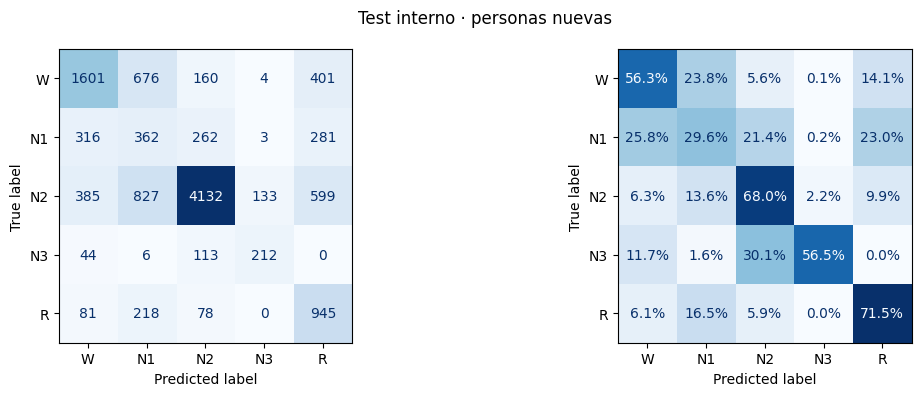

In [4]:
mostrar_errores_final(RESULTADO_FINAL)

### 4.8.4. Precision-Recall y Average Precision
Cada etapa contra el resto. Precisión frente a recuperación al variar el umbral, referencia horizontal de prevalencia y AP. Argmax marca la decisión multiclase congelada; no se optimizan umbrales con test.

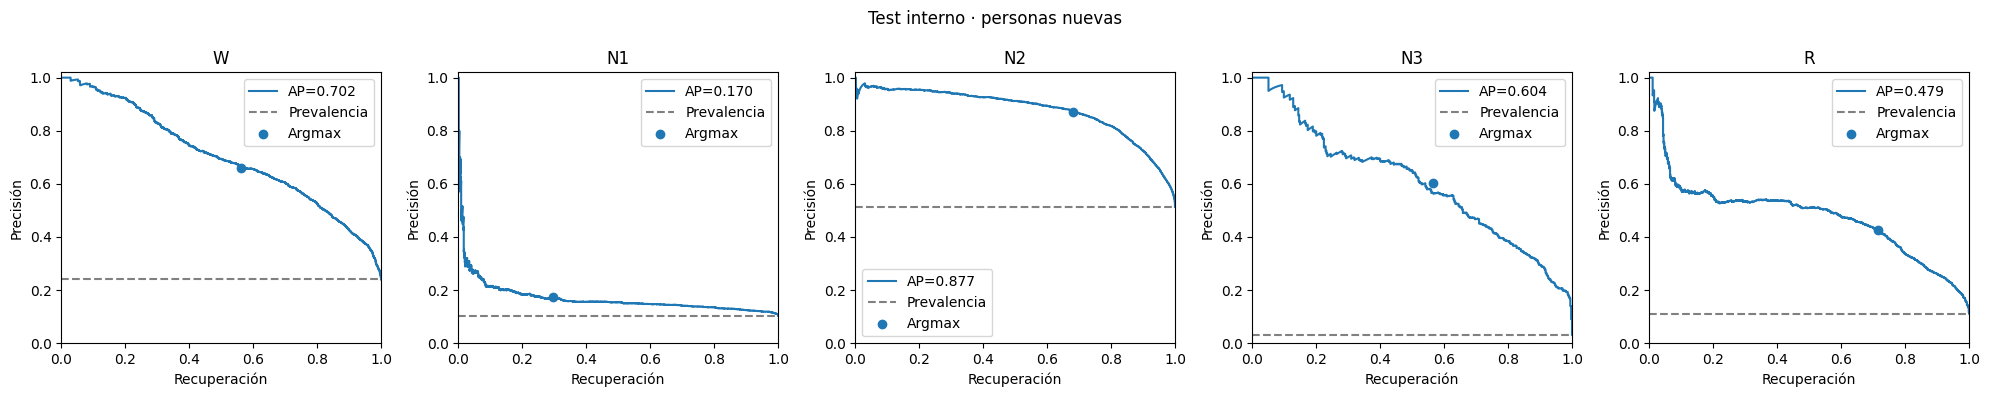

Etapa,AP
W,0.7021
N1,0.1699
N2,0.8774
N3,0.6036
R,0.4794


In [5]:
mostrar_curvas_final(RESULTADO_FINAL,'pr')

### 4.8.5. ROC y ROC-AUC
Diagnóstico complementario a PR. Una ROC-AUC alta no reemplaza precisión y recuperación de una etapa minoritaria.

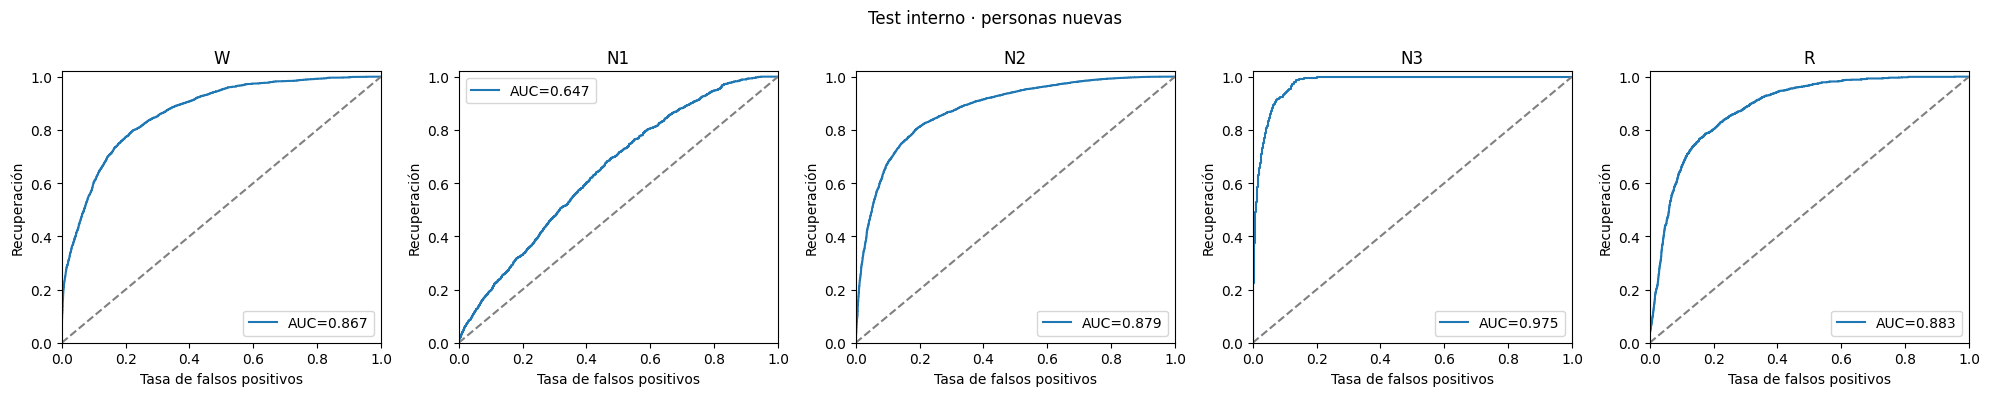

Etapa,ROC-AUC
W,0.8669
N1,0.6471
N2,0.8787
N3,0.9746
R,0.8833


In [6]:
mostrar_curvas_final(RESULTADO_FINAL,'roc')

### 4.8.6. Resultados por paciente
F1 con cinco etapas fijas y cobertura informada. Las personas tienen diferente duración y presencia de etapas; ausencia de clases limita su comparación. Se muestra todo el test: 16 pacientes.

In [7]:
PACIENTES_TEST_FINAL = pd.read_csv(DIRECTORIO_FINAL/'test_final/pacientes_test.csv')
tabla_final(PACIENTES_TEST_FINAL.sort_values('f1_macro_5_etapas').rename(columns={
    'patient_id':'Paciente','epochs':'Epochs','etapas_presentes':'Etapas presentes',
    'f1_macro_5_etapas':'F1 macro (5 etapas)','exactitud':'Exactitud'}))
tabla_final(PACIENTES_TEST_FINAL[['f1_macro_5_etapas','exactitud']].agg(['mean','std','min','max']),
    'Dispersión entre pacientes — no equivale al agregado por epoch')

,Paciente,Epochs,Etapas presentes,F1 macro (5 etapas),Exactitud
13,83,731,4,0.1913,0.3748
14,85,616,4,0.2351,0.3425
12,67,821,4,0.3433,0.3800
1,6,801,4,0.3926,0.5431
0,2,652,4,0.4011,0.5874
9,50,696,5,0.4118,0.8750
10,53,756,4,0.4210,0.5939
15,88,713,4,0.4303,0.5891
11,56,809,4,0.4372,0.6823
2,12,843,4,0.4539,0.6394


**Dispersión entre pacientes — no equivale al agregado por epoch**

,f1_macro_5_etapas,exactitud
mean,0.4288,0.6121
std,0.1117,0.1475
min,0.1913,0.3425
max,0.6369,0.8750


### 4.8.7. Evolución y comparación validación–test
Se conservan las decisiones de desarrollo. Los resultados históricos sobre 76 pacientes no son una réplica de la validación actual sobre 60; se identifican por separado. Validación y test no se promedian. Las diferencias se describen, sin nuevos ajustes.

In [8]:
EVOLUCION_FINAL = pd.DataFrame(PLANTILLA_FINAL['evolucion'] + [dict(etapa='Modelo congelado',
    conjunto='Test · 16 personas nuevas',f1_macro=RESULTADO_FINAL['metricas']['f1_macro'],
    desviacion=np.nan,exactitud=RESULTADO_FINAL['metricas']['exactitud'])])
tabla_final(EVOLUCION_FINAL.rename(columns={'etapa':'Paso','conjunto':'Evaluación','f1_macro':'F1 macro',
    'desviacion':'Desviación entre folds','exactitud':'Exactitud'}))
tabla_final(pd.DataFrame([{'Referencia':'XGBoost ponderado anterior','Cohorte':'76 pacientes · sin test reservado',
    'F1 macro':0.4923,'Desviación entre folds':0.0217,'Exactitud':0.5921}]),
    'Antecedente histórico — otra partición; no atribuir diferencias solo al modelo')
etapas_cv = pd.DataFrame(PLANTILLA_FINAL['referencia_validacion']['por_etapa']).T
etapas_test = pd.read_csv(DIRECTORIO_FINAL/'test_final/etapas_test.csv').set_index('etapa')
comparacion = pd.DataFrame({'F1 validación (media folds)':etapas_cv.f1,
    'F1 test (agregado)':etapas_test.f1,'Precisión test':etapas_test.precision,
    'Recuperación test':etapas_test.recuperacion,'Soporte test':etapas_test.soporte}).reindex(PLANTILLA_FINAL['etapas'])
tabla_final(comparacion,'Comparación por etapa')
diferencia = RESULTADO_FINAL['metricas']['f1_macro'] - PLANTILLA_FINAL['referencia_validacion']['f1_macro']
print(f'F1 test menos validación: {diferencia:+.4f}. Son evaluaciones distintas; no es efecto causal ni prueba de superioridad.')
debil = etapas_test.f1.idxmin()
print(f'Etapa de menor F1 en test: {debil} ({etapas_test.loc[debil,"f1"]:.4f}). No se reajusta el modelo con este resultado.')

Paso,Evaluación,F1 macro,Desviación entre folds,Exactitud
Referencia ponderada,Validación por pacientes · 60 personas,0.4859,0.0299,0.5867
Ajuste: reg_lambda=5,Validación por pacientes · 60 personas,0.4907,0.0327,0.5899
Historia de 1+2 minutos,Validación por pacientes · 60 personas,0.5053,0.0265,0.6043
Modelo congelado,Test · 16 personas nuevas,0.5412,—,0.6126


**Antecedente histórico — otra partición; no atribuir diferencias solo al modelo**

Referencia,Cohorte,F1 macro,Desviación entre folds,Exactitud
XGBoost ponderado anterior,76 pacientes · sin test reservado,0.4923,0.0217,0.5921


**Comparación por etapa**

,F1 validación (media folds),F1 test (agregado),Precisión test,Recuperación test,Soporte test
W,0.5757,0.6077,0.6597,0.5633,2842
N1,0.2411,0.2185,0.1733,0.2958,1224
N2,0.7657,0.7637,0.8708,0.6801,6076
N3,0.4999,0.5832,0.6023,0.5653,375
R,0.4442,0.5327,0.4245,0.7148,1322


F1 test menos validación: +0.0358. Son evaluaciones distintas; no es efecto causal ni prueba de superioridad.
Etapa de menor F1 en test: N1 (0.2185). No se reajusta el modelo con este resultado.


## 4.9. Conclusiones y limitaciones

La revisión entrega un candidato por pacientes separados y otro por epochs mezclados, ambos con wearable + PSG. Los resultados de desarrollo se presentan en 4.5 y 4.6: sus valores responden preguntas distintas. Las cifras mezcladas no demuestran, por sí solas, generalización a personas nuevas; la proximidad temporal y las señales compartidas por los retardos pueden favorecerlas.

La sección 4.8 conserva la evaluación histórica del candidato anterior como referencia. La comparación de los candidatos actuales sobre los mismos pacientes adicionales corresponde a 4.7 y queda pendiente mientras esos CSV no estén disponibles. Su resultado contrastará estos candidatos concretos, sin demostrar superioridad universal de un protocolo.

Se informan métricas por etapa y paciente para examinar clases escasas y heterogeneidad individual. La exposición histórica del test interno y la selección entre muchas pruebas limitan la interpretación. No se reajustan modelos a partir de la comparación adicional. SMOTE y contexto temporal se estudian por separado.
